<div align="center"><h2>PneuNet E5 — Ablasi Data, Batch Fisik 32, Weighted BCE</h2><p>NORMAL dan PNEUMONIA | PyTorch CUDA | Lima kondisi data</p></div>

## Abstrak <a id="abstrak"></a>
Salinan terkontrol dari notebook SE batch32, dengan arsitektur **E5** dari notebook ablation E0–E6.
Arsitektur tetap E5 untuk semua eksperimen: residual detail aktif, bottleneck fusion nonaktif,
residual context aktif, dan normalized learnable pooling aktif (**785.192 parameter trainable**).
Yang diablasikan adalah data: **baseline RAW 0–255**, **RAW + normalisasi /255**, **RAW + CLAHE**,
**RAW + rotasi pada 50% train**, dan **RAW + Gaussian blur pada 50% train**.

Baseline di sini sengaja BERBEDA dari baseline notebook asal yang sudah /255, sesuai pilihan pengguna.
Semua kondisi memakai grayscale dan letterbox 224×224 yang sama; hanya kondisi normalisasi memakai /255.
CLAHE tidak digabung rotasi/blur. Rotasi dan blur memakai subset 50% train yang sama,
dengan parameter tetap, tanpa duplikasi gambar dan tanpa augmentasi online tambahan.
Validation/test utama tidak dirotasi/diblur; kondisi CLAHE dan normalisasi memakai preprocessing yang sama di setiap split.

**Status:** EDA dan audit teknis boleh dijalankan tanpa training. Hasil full, error counts,
dan Grad-CAM tidak diisi dari eksperimen lama atau angka dummy. Ini eksperimen riset, bukan validasi klinis.

**Validasi teknis selesai:** EDA lima kondisi telah dieksekusi, parameter/forward E5 identik dengan referensi, serta satu update CPU mini-fixture per kondisi finite. Ini bukan full training atau smoke GPU batch32. Belum ada accuracy/angka raw-benar → kondisi-salah eksperimen baru; jalankan full training untuk menghitungnya.

# Daftar isi
1. [Environment dan konfigurasi](#configuration)
2. [Dataset dan EDA raw](#dataset)
3. [Preprocessing serta EDA semua kondisi](#preprocessing)
4. [Model E5 dan protokol training](#modeling)
5. [Training / smoke / laporan tersimpan](#training)
6. [Confusion matrix dan classification report](#classification-reports)
7. [Grad-CAM](#gradcam)
8. [RAW benar → kondisi salah: analisis berpasangan](#paired-errors)
9. [Interpretasi dan provenance](#kesimpulan)

# Environment dan konfigurasi <a id="configuration"></a>
Gunakan kernel PyTorch CUDA yang sama dengan notebook asal (`~/.venv/bin/python`).
Default aman: `RUN_TRAINING=False`, mode `smoke`. Untuk training 5 kondisi, pilih `True` dan `full` secara eksplisit.
Notebook tidak memuat NPZ lama, checkpoint SE/E0/E6, atau hasil lama sebagai hasil E5.
Data, figure, cache dan checkpoint baru berada pada namespace output khusus notebook ini.
GPU server dipakai bersama; periksa ketersediaan sebelum memulai full training.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import sys
import numpy as np
WORKSPACE = (Path.home() / 'riset dosen' / 'Pneumonia').resolve()
ROOT = WORKSPACE / 'Datasets' / 'chest_xray'
CACHE_ROOT = WORKSPACE / 'tmp' / 'e5_data_ablation_cache'
OUTPUT_ROOT = WORKSPACE / 'output_pneunet_e5_data_ablation_batch32'
MODELING_WORKSPACE = WORKSPACE
MODELING_RESULTS_ROOT = OUTPUT_ROOT / 'modeling'
REPORT_OUTPUT_DIR = OUTPUT_ROOT / 'notebook_reports'
REPORT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAVED_RUN_DIR = MODELING_RESULTS_ROOT
REFERENCE_RUN_DIR = None
RUN_TRAINING = False
MODELING_RUN_MODE = 'smoke'
RUN_GRADCAM = True
RUN_PAIRED_INPUT_DIAGNOSTIC = True
RUN_ARCHITECTURE_AUDIT = True
DATA_EDA_COMPLETED = False
USE_CLASS_WEIGHTING = True
LOSS_VERSION = 'inverse_frequency_weighted_bce_v1'
ARCH_VERSION = 'pneunet_E5_fixed_data_ablation_raw255_v1'
SEED = 42
IMG_SIZE = 224
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
LABEL2ID = {name:i for i,name in enumerate(CLASS_NAMES)}
SPLIT_NAMES = ('train','val','test')
EXPECTED_SPLIT_COUNTS = {'train':4646,'val':586,'test':624}
IMAGE_EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.gif','.tif','.tiff','.webp'}
EDA_SAMPLES_PER_CLASS = 5
EDA_INTENSITY_SAMPLES = 300
PREPROCESS_CHUNK_SIZE = 64
CLAHE_CLIP_LIMIT = 2.5
CLAHE_TILE_GRID_SIZE = (8,8)
ROTATION_MAX_DEGREES = 15.
GAUSSIAN_SIGMA_RANGE = (0.5,1.5)
CPU_THREADS = 2
DEVICE_REQUEST = 'cuda:2'
EXPECTED_PYTHON = Path(sys.executable).resolve()
DATALOADER_WORKERS = 0
PIN_MEMORY = True
DETERMINISTIC = True
CUBLAS_WORKSPACE = ':4096:8'
MODEL_NAMES = ('PneuNet',)  # Legacy reporting key; build_model always builds E5, never SE/E0.
DATA_CONDITIONS = ('baseline','normalization','clahe','rotation50','gaussian50')
CONDITION_LABELS = {'baseline':'RAW baseline (0–255)', 'normalization':'RAW + /255 (0–1)',
    'clahe':'RAW + CLAHE (0–255)', 'rotation50':'RAW + rotasi 50%', 'gaussian50':'RAW + blur 50%'}
SELECTED_MODELS = list(MODEL_NAMES)
SELECTED_CONDITIONS = list(DATA_CONDITIONS)
TRAIN_CONFIG = {
    'use_class_weighting':USE_CLASS_WEIGHTING,'loss_version':LOSS_VERSION,
    'seed':SEED,'image_size':IMG_SIZE,'batch_size':32,'epochs':50,
    'learning_rate':0.001,'beta_1':0.9,'beta_2':0.999,'epsilon':1e-7,
    'dropout':0.3,'l2':0.001,'early_stopping_patience':7,
    'bn_eps':0.001,'bn_momentum':0.01,'threshold':0.5,'initial_weights':None,
}
SMOKE_CONFIG = {'train_samples':32,'validation_samples':32,'batch_size':32,
    'epochs':1,'steps_per_epoch':1,'validation_steps':1}
CLASSIFICATION_REPORT_SPLITS = ('train','val','test')
CLASSIFICATION_REPORT_EXPORT = True
ERROR_ANALYSIS_MODEL = 'PneuNet'
ERROR_ANALYSIS_CONDITION = 'baseline'
ERROR_ANALYSIS_MAX_CASES = 6
PAIRED_ERROR_EXAMPLES = 10
GRADCAM_ALPHA = .70
GRADCAM_TARGET_LAYERS = {'PneuNet':'context_refine.1.relu_out'}
E5_FLAGS = {'detail':True,'fusion':False,'context':True,'normalized':True}
ABLATION_CONFIGS = {'E5':E5_FLAGS}
assert MODELING_RUN_MODE in ('smoke','full')
assert set(SELECTED_CONDITIONS) <= set(DATA_CONDITIONS) and SELECTED_CONDITIONS
print('Architecture E5:',E5_FLAGS,'| train:',RUN_TRAINING,'| mode:',MODELING_RUN_MODE)
print('Baseline RAW 0–255; /255 hanya normalization; augmentation train-only 50%.')

def resolve_saved_run_dir(root, model_names, conditions, architecture_version=None):
    """Terima folder run atau pilih run full lengkap terbaru dalam folder modeling."""
    import json as run_json
    if root is None:
        return None
    root = Path(root)
    if not root.is_dir():
        return None
    candidates = sorted(
        (p for p in root.glob("pytorch_full_*") if p.is_dir()),
        key=lambda p: p.stat().st_mtime_ns, reverse=True,
    )
    for candidate in [root, *candidates]:
        complete = True
        for model_name in model_names:
            for condition in conditions:
                directory = candidate / f"{model_name}__{condition}"
                files = ("result.json", "full_history.csv", "best.pt",
                         "train_predictions.csv", "val_predictions.csv", "test_predictions.csv")
                if not all((directory / name).is_file() for name in files):
                    complete = False
                    break
                try:
                    info = run_json.loads((directory / "result.json").read_text(encoding="utf-8"))
                except (OSError, ValueError):
                    complete = False
                    break
                if (info.get("mode") != "full" or info.get("status") != "COMPLETE"
                        or not info.get("test_evaluated") or info.get("model") != model_name
                        or info.get("condition") != condition
                        or (architecture_version is not None
                            and info.get("architecture_version") != architecture_version)):
                    complete = False
                    break
            if not complete:
                break
        if complete:
            return candidate
    return None

Architecture E5: {'detail': True, 'fusion': False, 'context': True, 'normalized': True} | train: False | mode: smoke
Baseline RAW 0–255; /255 hanya normalization; augmentation train-only 50%.


## Import pustaka dan inisialisasi

Pustaka dimuat sekali dari kernel ai_env. Seed Python, NumPy, dan PyTorch mengikuti konfigurasi. Sel berhenti jika interpreter berbeda atau CUDA tidak tersedia.

In [2]:
import os
import sys
import re
import gc
import json
import math
import random
import shutil
import hashlib
import tempfile
import zipfile
import time
from datetime import datetime

# Conda DLL search path before SciPy/OpenCV/Torch on Windows.
_conda_bin = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and _conda_bin.is_dir():
    os.environ["PATH"] = str(_conda_bin) + os.pathsep + os.environ.get("PATH", "")
    _conda_dll_handle = os.add_dll_directory(str(_conda_bin))
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", CUBLAS_WORKSPACE)
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import pandas as pd
import cv2
cv2.setNumThreads(CPU_THREADS)
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import Image as NotebookImage, display
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
if Path(sys.executable).resolve() != EXPECTED_PYTHON.resolve():
    raise RuntimeError("Kernel Python berbeda dari interpreter pada konfigurasi.")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA tidak tersedia. Gunakan kernel dengan PyTorch CUDA.")
DEVICE = torch.device(DEVICE_REQUEST)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(DEVICE))

/mnt/extended-home/arsyadmuhammad/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /mnt/extended-home/arsyadmuhammad/.venv/bin/python
PyTorch: 2.5.1+cu121 | torchvision: 0.20.1+cu121
Device: cuda:2 | NVIDIA L40


# Dataset
<a id="dataset"></a>
<a id="1-load-data"></a>

## [1] Lokasi dataset dan inventaris gambar

Baca file citra dari folder fisik `train`, `val`, dan `test`. Metadata sistem tidak dihitung.
Label `NORMAL=0` dan `PNEUMONIA=1`; nama file menjadi sumber perkiraan subtipe dan ID pasien.

In [3]:
for split in SPLIT_NAMES:
    for label in CLASS_NAMES:
        folder = ROOT / split / label
        if not folder.is_dir():
            raise FileNotFoundError(f"Folder dataset tidak ditemukan: {folder}")
print("ROOT:", ROOT)

ROOT: /mnt/extended-home/arsyadmuhammad/riset dosen/Pneumonia/Datasets/chest_xray


In [4]:
rows = []
for split in SPLIT_NAMES:
    for label in CLASS_NAMES:
        for p in sorted((ROOT / split / label).rglob("*")):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({"path": str(p), "orig_split": split, "label": label})

df = pd.DataFrame(rows)
df["y"] = df["label"].map(LABEL2ID)   # KENAPA: model butuh angka 0/1, bukan string

# Perkiraan kelompok sumber dari nama, mis. NORMAL-1064313-0001.jpeg atau BACTERIA-2034017-0005.jpeg.
fname = df["path"].apply(os.path.basename)
df["subtype"] = np.where(fname.str.contains("bacteria", case=False), "bacteria",
                 np.where(fname.str.contains("virus", case=False), "virus", "normal"))
df["patient"] = fname.str.extract(r"((?:NORMAL|BACTERIA|VIRUS)-\d+|person\d+|IM-\d+)", expand=False, flags=re.IGNORECASE)   # kelompok sumber perkiraan, bukan ID terverifikasi

print("Total citra:", len(df))
y = df["y"].to_numpy(dtype=np.int64)
display(df.head())

Total citra: 5856


,path,orig_split,label,y,subtype,patient
0,/mnt/extended-home/arsyadmuhammad/riset dosen/...,train,NORMAL,0,normal,NORMAL-1014768
1,/mnt/extended-home/arsyadmuhammad/riset dosen/...,train,NORMAL,0,normal,NORMAL-1023731
2,/mnt/extended-home/arsyadmuhammad/riset dosen/...,train,NORMAL,0,normal,NORMAL-1029510
3,/mnt/extended-home/arsyadmuhammad/riset dosen/...,train,NORMAL,0,normal,NORMAL-1034239
4,/mnt/extended-home/arsyadmuhammad/riset dosen/...,train,NORMAL,0,normal,NORMAL-1044645


## [2] Tetapkan indeks split dan validasi jumlah data

Split mengikuti folder lokal: train 4.646, validation 586, dan test 624 gambar.
Validation telah diambil secara stratified dari train sebelumnya; test bawaan dipertahankan.
Sel ini hanya membaca pembagian yang sudah ada, tanpa memindahkan atau membagi ulang file.

In [5]:
train_idx = df.index[df["orig_split"] == "train"].to_numpy()
val_idx = df.index[df["orig_split"] == "val"].to_numpy()
test_idx = df.index[df["orig_split"] == "test"].to_numpy()

splits = {"train": train_idx, "val": val_idx, "test": test_idx}
summary = pd.DataFrame({
    s: {"total": len(ix),
        "NORMAL": int((y[ix] == 0).sum()),
        "PNEUMONIA": int((y[ix] == 1).sum()),
        "% pneumonia": round(100 * (y[ix] == 1).mean(), 1)}
    for s, ix in splits.items()
}).T
print(summary)

assert df["path"].is_unique
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)
assert (len(train_idx), len(val_idx), len(test_idx)) == tuple(EXPECTED_SPLIT_COUNTS[s] for s in SPLIT_NAMES)
print("\nOK: split mengikuti folder lokal dan setiap path masuk tepat satu subset.")

        total  NORMAL  PNEUMONIA  % pneumonia
train  4646.0  1198.0     3448.0         74.2
val     586.0   151.0      435.0         74.2
test    624.0   234.0      390.0         62.5

OK: split mengikuti folder lokal dan setiap path masuk tepat satu subset.


# Exploratory Data Analysis
<a id="eda"></a>
<a id="2-eda"></a>

Eksplorasi berikut memeriksa ketimpangan kelas, variasi ukuran dan intensitas, contoh citra,
serta potensi irisan pasien. Hasilnya menjelaskan kebutuhan preprocessing dan batas interpretasi eksperimen.

## [1] Distribusi kelas dan subtipe pneumonia

In [6]:
ct = pd.crosstab(df["orig_split"], df["label"], margins=True)
print(ct)

total = df["label"].value_counts()
print("\nProporsi kelas (seluruh data):")
print((total / total.sum()).round(3))
print("\nRasio Pneumonia : Normal =", round(total["PNEUMONIA"] / total["NORMAL"], 2), ": 1")

# Klaim paper
print("\nKlaim paper  : Normal=3907, Pneumonia=1949")
print("Data asli    : Normal=%d, Pneumonia=%d" % (total["NORMAL"], total["PNEUMONIA"]))

label       NORMAL  PNEUMONIA   All
orig_split                         
test           234        390   624
train         1198       3448  4646
val            151        435   586
All           1583       4273  5856

Proporsi kelas (seluruh data):
label
PNEUMONIA    0.73
NORMAL       0.27
Name: count, dtype: float64

Rasio Pneumonia : Normal = 2.7 : 1

Klaim paper  : Normal=3907, Pneumonia=1949
Data asli    : Normal=1583, Pneumonia=4273


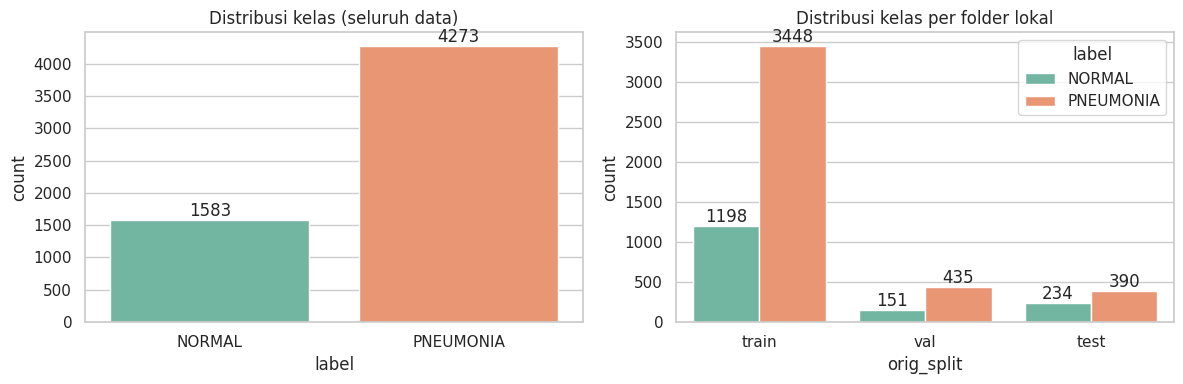

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a) per kelas keseluruhan
sns.countplot(data=df, x="label", order=CLASS_NAMES, hue="label", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Distribusi kelas (seluruh data)")
for c in axes[0].containers:
    axes[0].bar_label(c)

# (b) per folder asli x kelas
sns.countplot(data=df, x="orig_split", order=["train", "val", "test"], hue="label",
              hue_order=CLASS_NAMES, palette="Set2", ax=axes[1])
axes[1].set_title("Distribusi kelas per folder lokal")
for c in axes[1].containers:
    axes[1].bar_label(c)

plt.tight_layout(); plt.show()
# KENAPA countplot: otomatis menghitung frekuensi tiap kategori, tidak perlu groupby manual.
# KENAPA bar_label: menampilkan angka di atas batang agar mudah dibaca saat presentasi.

subtype
bacteria    2780
virus       1493
Name: count, dtype: int64


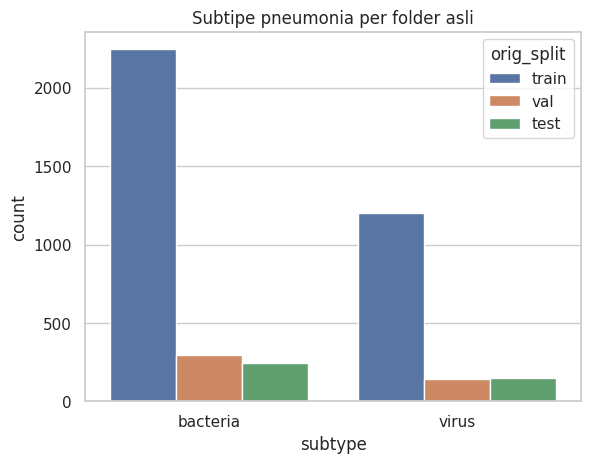

In [8]:
print(df[df.label == "PNEUMONIA"]["subtype"].value_counts())
sns.countplot(data=df[df.label == "PNEUMONIA"], x="subtype", hue="orig_split")
plt.title("Subtipe pneumonia per folder asli"); plt.show()

## [2] Ukuran gambar dan rasio aspek

Ukur lebar, tinggi, serta rasio aspek gambar asli. Variasi rasio aspek menjadi alasan menggunakan
letterbox agar bentuk anatomi dipertahankan saat membentuk input persegi.

Ukuran citra:   0%|          | 0/5856 [00:00<?, ?it/s]

Ukuran citra:   0%|          | 24/5856 [00:00<00:41, 141.66it/s]

Ukuran citra:   1%|          | 39/5856 [00:00<00:52, 110.40it/s]

Ukuran citra:   1%|          | 66/5856 [00:00<00:41, 138.15it/s]

Ukuran citra:   2%|▏         | 108/5856 [00:00<00:26, 217.76it/s]

Ukuran citra:   3%|▎         | 156/5856 [00:00<00:19, 292.61it/s]

... (204 outputs left out)

Ukuran citra:  99%|█████████▉| 5817/5856 [00:32<00:00, 188.86it/s]

Ukuran citra: 100%|█████████▉| 5849/5856 [00:32<00:00, 207.66it/s]

Ukuran citra: 100%|██████████| 5856/5856 [00:32<00:00, 180.36it/s]

             w        h   aspect
count  5856.00  5856.00  5856.00
mean   1328.48   974.16     1.44
std     364.02   386.40     0.26
min     384.00   127.00     0.84
25%    1056.00   688.00     1.26
50%    1281.00   888.00     1.41
75%    1560.00  1195.50     1.58
max    2916.00  2713.00     3.38


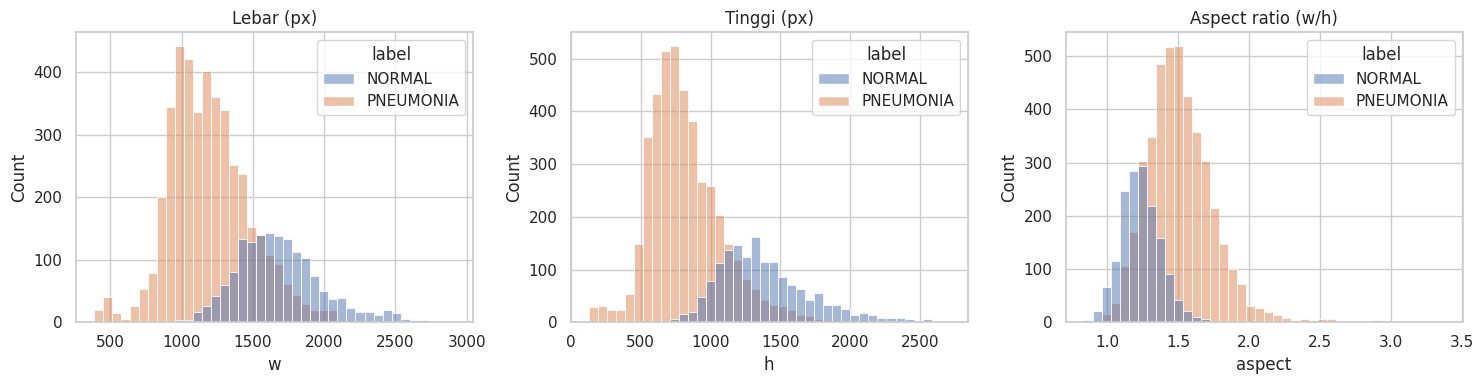

In [9]:
def image_dimensions(path):
    with Image.open(path) as image:
        return image.size

sizes = [image_dimensions(p) for p in tqdm(df["path"], desc="Ukuran citra")]
df["w"] = [s[0] for s in sizes]
df["h"] = [s[1] for s in sizes]
df["aspect"] = df["w"] / df["h"]

print(df[["w", "h", "aspect"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=df, x="w", hue="label", bins=40, ax=axes[0]); axes[0].set_title("Lebar (px)")
sns.histplot(data=df, x="h", hue="label", bins=40, ax=axes[1]); axes[1].set_title("Tinggi (px)")
sns.histplot(data=df, x="aspect", hue="label", bins=40, ax=axes[2]); axes[2].set_title("Aspect ratio (w/h)")
plt.tight_layout(); plt.show()
# KENAPA ada aspect ratio: resize paksa ke 224x224 akan mendistorsi citra yang bentuknya jauh dari persegi.

## [3] Contoh citra dan distribusi intensitas

Tampilkan sampel per kelas dengan seed tetap, kemudian ringkas intensitas sebelum preprocessing.

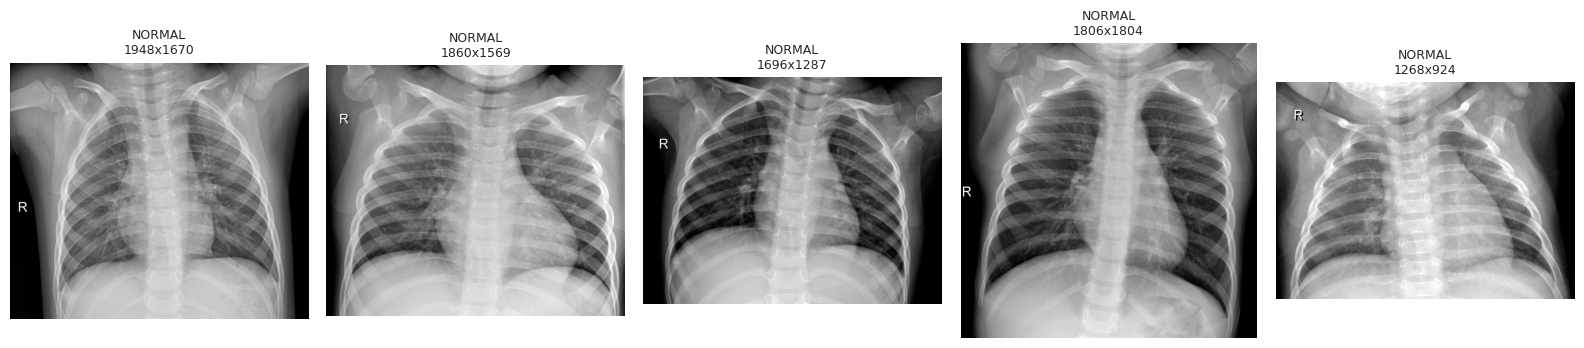

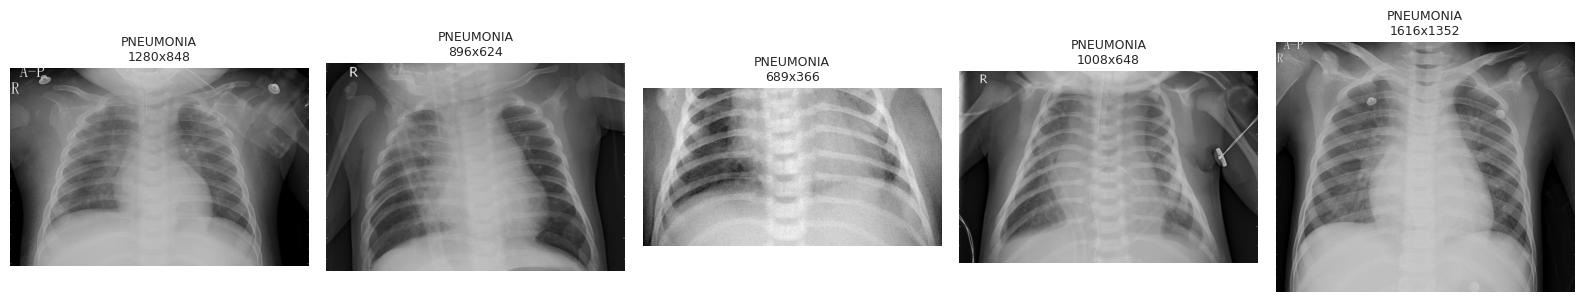

In [10]:
def show_samples(label, n=EDA_SAMPLES_PER_CLASS):
    sub = df[df.label == label].sample(n, random_state=SEED)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.4))
    for ax, (_, r) in zip  (axes, sub.iterrows()):
        img = cv2.imread(r["path"], cv2.IMREAD_GRAYSCALE)   # KENAPA IMREAD_GRAYSCALE: X-ray memang 1 kanal; hemat memori & sesuai paper
        ax.imshow(img, cmap="gray")                          # KENAPA cmap="gray": tanpa ini matplotlib memberi warna palsu (viridis)
        ax.set_title(f"{label}\n{img.shape[1]}x{img.shape[0]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()

show_samples("NORMAL")
show_samples("PNEUMONIA")

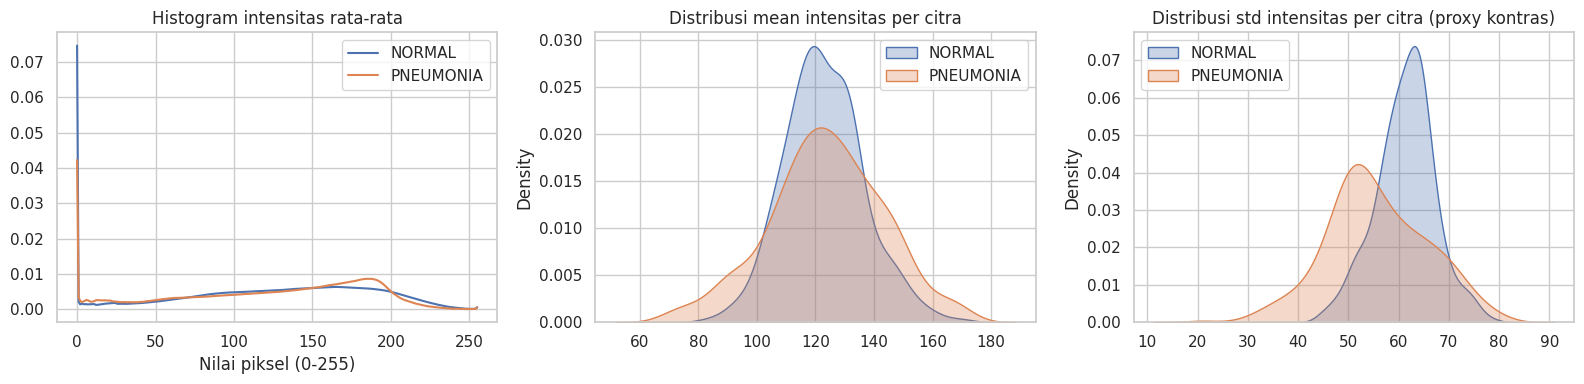

NORMAL | mean=122.8 | std=61.3
PNEUMONIA | mean=123.5 | std=55.6


In [11]:
def intensity_stats(label, n=EDA_INTENSITY_SAMPLES):
    sub = df[df.label == label].sample(n, random_state=SEED)
    means, stds, hist = [], [], np.zeros(256)
    for p in sub["path"]:
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        means.append(img.mean()); stds.append(img.std())
        hist += np.bincount(img.ravel(), minlength=256)   # KENAPA bincount: hitung frekuensi tiap nilai 0..255 jauh lebih cepat dari plt.hist per citra
    return np.array(means), np.array(stds), hist / hist.sum()

stats = {c: intensity_stats(c) for c in CLASS_NAMES}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for c in CLASS_NAMES:
    m, s, h = stats[c]
    axes[0].plot(h, label=c)
    sns.kdeplot(m, ax=axes[1], label=c, fill=True, alpha=0.3)
    sns.kdeplot(s, ax=axes[2], label=c, fill=True, alpha=0.3)
axes[0].set_title("Histogram intensitas rata-rata"); axes[0].set_xlabel("Nilai piksel (0-255)")
axes[1].set_title("Distribusi mean intensitas per citra")
axes[2].set_title("Distribusi std intensitas per citra (proxy kontras)")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

for c in CLASS_NAMES:
    print(c, "| mean=%.1f | std=%.1f" % (stats[c][0].mean(), stats[c][1].mean()))

## [4] Pemeriksaan potensi leakage pasien

ID diekstrak dari nama file dan hanya merupakan perkiraan; format ID tidak konsisten antar kelas/subset.
Nilai yang tidak dikenali dikeluarkan dari himpunan ID. Irisan yang muncul perlu ditinjau sebagai potensi
leakage, sedangkan irisan nol belum membuktikan independensi pasien tanpa metadata pasien resmi.

Dataset lokal memakai pola `NORMAL-<nomor>-<urutan>`, `BACTERIA-<nomor>-<urutan>`, dan `VIRUS-<nomor>-<urutan>`. Prefix dan nomor digabung menjadi kelompok sumber perkiraan. Tanpa metadata resmi, nomor ini belum dapat dipastikan sebagai identitas pasien.

Pada dataset saat pemeriksaan, 229 kelompok sumber perkiraan muncul pada train dan validation. Pembagian fisik yang sudah ada dipertahankan; ini adalah split per gambar, bukan split pasien yang terverifikasi. Hasil EDA ini perlu ikut dicatat saat melaporkan eksperimen.

In [12]:
per_patient = df.groupby("patient").size()
print("Jumlah pasien unik (perkiraan):", per_patient.shape[0])
print("Rata-rata citra per pasien   :", round(per_patient.mean(), 2))
print("Maks citra per pasien        :", per_patient.max())

# Pasien yang muncul di lebih dari satu folder asli
multi = df.groupby("patient")["orig_split"].nunique()
print("Pasien yang tersebar di >1 folder asli:", (multi > 1).sum())

Jumlah pasien unik (perkiraan): 3890
Rata-rata citra per pasien   : 1.51
Maks citra per pasien        : 30
Pasien yang tersebar di >1 folder asli: 0


In [13]:
def patient_set(indices):
    # ID yang tidak terdeteksi tidak diperlakukan sebagai satu pasien bersama.
    return set(df.iloc[indices]["patient"].dropna())

for left, right in (("train", "val"), ("train", "test"), ("val", "test")):
    print(f"Irisan ID perkiraan {left}/{right}:", len(patient_set(splits[left]) & patient_set(splits[right])))
print("Citra tanpa ID yang dikenali:", int(df["patient"].isna().sum()))

Irisan ID perkiraan train/val: 0
Irisan ID perkiraan train/test: 0
Irisan ID perkiraan val/test: 0
Citra tanpa ID yang dikenali: 0


# Preprocessing dan EDA semua kondisi <a id="preprocessing"></a>
Semua tahap di bawah selesai SEBELUM modeling. Sumber dan urutan split sama dengan notebook asal.

| Kondisi | Train | Validation/test utama | Skala input model |
|---|---|---|---|
| baseline | grayscale + letterbox | sama | float32 0–255 |
| normalization | RAW baseline /255 | sama | float32 0–1 |
| clahe | CLAHE sebelum letterbox; tanpa augmentasi | sama | float32 0–255 |
| rotation50 | tepat 50% train dirotasi; 50% raw | raw bersih, tanpa rotasi | float32 0–255 |
| gaussian50 | tepat 50% train diblur; 50% raw | raw bersih, tanpa blur | float32 0–255 |

“RAW” berarti grayscale hasil file sumber, dengan letterbox sebagai penyesuaian ukuran bersama.
Tidak memakai gamma, ImageNet/z-score normalization, CLAHE pada jalur augmentasi, atau sampling ulang per epoch.
Kuota dibagi per kelas (train genap: tepat 50% per kelas), seed42. Jumlah gambar tidak bertambah.
Rencana mask val/test hanya untuk diagnostik terpisah dan tidak dipakai pada evaluasi utama.
Original image dan processed image ditampilkan berpasangan; histogram memakai sumbu numerik sesuai skala masing-masing.

In [14]:
def apply_clahe(img):
    """CLAHE standar khusus jalur CLAHE, sebelum padding."""
    if img.ndim != 2 or img.dtype != np.uint8 or img.size == 0:
        raise ValueError("CLAHE membutuhkan citra grayscale uint8 yang tidak kosong.")
    transform = cv2.createCLAHE(
        clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID_SIZE,
    )
    return transform.apply(img)


def letterbox(img, size=IMG_SIZE, pad_value=0):
    """Skalakan citra grayscale secara isotropik dan pusatkan pada kanvas persegi."""
    if img.ndim != 2 or img.size == 0:
        raise ValueError("Letterbox membutuhkan citra grayscale dua dimensi yang tidak kosong.")
    if size <= 0:
        raise ValueError("Ukuran target harus positif.")
    h, w = img.shape
    scale = size / max(h, w)
    new_w = max(1, min(size, int(round(w * scale))))
    new_h = max(1, min(size, int(round(h * scale))))
    interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(img, (new_w, new_h), interpolation=interpolation)
    canvas = np.full((size, size), pad_value, dtype=img.dtype)
    top = (size - new_h) // 2
    left = (size - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = resized
    return canvas

In [15]:
def gaussian_blur(img, sigma=1.0):
    if not 0 < sigma:
        raise ValueError('Sigma harus positif.')
    return cv2.GaussianBlur(img, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma),
                            borderType=cv2.BORDER_REFLECT_101)


def rotate_image(img, angle):
    height, width = img.shape
    matrix = cv2.getRotationMatrix2D(((width - 1) / 2, (height - 1) / 2), float(angle), 1.)
    return cv2.warpAffine(img, matrix, (width, height), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT_101)


def stratified_half_mask(labels, seed=SEED):
    """Exactly floor(N/2), with per-class quotas differing from 50% by <1 image."""
    labels = np.asarray(labels)
    classes, counts = np.unique(labels, return_counts=True)
    quotas = counts // 2
    remaining = len(labels) // 2 - int(quotas.sum())
    fractional = (counts % 2).astype(int)
    for pos in sorted(range(len(classes)), key=lambda j: (-fractional[j], int(classes[j])))[:remaining]:
        quotas[pos] += 1
    rng = np.random.default_rng(seed)
    mask = np.zeros(len(labels), dtype=bool)
    for value, quota in zip(classes, quotas):
        indices = np.flatnonzero(labels == value)
        mask[rng.permutation(indices)[:int(quota)]] = True
    assert int(mask.sum()) == len(labels) // 2
    return mask


def make_augmentation_plan(source_frame, seed=SEED):
    plan = source_frame[['path', 'orig_split', 'label', 'y']].copy()
    plan['selected_50pct'] = False
    plan['rotation_degrees'] = 0.
    plan['gaussian_sigma'] = 0.
    for offset, split in enumerate(SPLIT_NAMES):
        indices = plan.index[plan.orig_split == split].to_numpy()
        mask = stratified_half_mask(plan.loc[indices, 'y'].to_numpy(), seed + 100 * offset)
        selected = indices[mask]
        rng = np.random.default_rng(seed + 100 * offset + 1)
        plan.loc[selected, 'selected_50pct'] = True
        plan.loc[selected, 'rotation_degrees'] = rng.uniform(-ROTATION_MAX_DEGREES, ROTATION_MAX_DEGREES, len(selected))
        plan.loc[selected, 'gaussian_sigma'] = rng.uniform(*GAUSSIAN_SIGMA_RANGE, len(selected))
    plan['augmented_in_main_experiment'] = plan.selected_50pct & (plan.orig_split == 'train')
    plan['selection_usage'] = np.where(plan.orig_split == 'train', 'training', 'diagnostic_only_not_main_eval')
    return plan


class ConditionImages:
    """Lazy float32 view of shared uint8 cache; no hidden normalization or online RNG."""
    def __init__(self, raw, clahe, source_indices, condition, plan, diagnostic=False):
        if condition not in DATA_CONDITIONS:
            raise ValueError(condition)
        self.raw, self.clahe = raw, clahe
        self.indices = np.asarray(source_indices, dtype=int)
        self.condition, self.plan, self.diagnostic = condition, plan, bool(diagnostic)
        self.shape = (len(self.indices), IMG_SIZE, IMG_SIZE)
        self.dtype = np.dtype('float32')

    def __len__(self):
        return len(self.indices)

    def one(self, local_index):
        index = int(self.indices[int(local_index)])
        row = self.plan.iloc[index]
        source = self.clahe[index] if self.condition == 'clahe' else self.raw[index]
        img = np.array(source, dtype=np.float32, copy=True)
        if self.condition == 'normalization':
            img /= 255.
        eligible_split = row.orig_split == 'train' or self.diagnostic
        if self.condition in ('rotation50', 'gaussian50') and eligible_split and row.selected_50pct:
            img = (rotate_image(img, row.rotation_degrees) if self.condition == 'rotation50'
                   else gaussian_blur(img, row.gaussian_sigma))
        maximum = 1. if self.condition == 'normalization' else 255.
        if img.shape != (IMG_SIZE, IMG_SIZE) or not np.isfinite(img).all() or img.min() < -1e-5 or img.max() > maximum + 1e-4:
            raise ValueError(f'Input tidak valid: {self.condition}/{index}')
        return np.clip(img, 0., maximum).astype(np.float32, copy=False)

    def __getitem__(self, index):
        if np.isscalar(index):
            return self.one(index)
        selected = np.arange(len(self))[index]
        selected = np.asarray(selected).reshape(-1)
        return (np.stack([self.one(i) for i in selected]) if len(selected)
                else np.empty((0, IMG_SIZE, IMG_SIZE), dtype=np.float32))


def validate_dataset_bundle(bundle):
    for condition in DATA_CONDITIONS:
        for split in SPLIT_NAMES:
            images, labels = bundle[condition][split]
            assert images.shape == (EXPECTED_SPLIT_COUNTS[split], IMG_SIZE, IMG_SIZE)
            assert images.dtype == np.dtype('float32')
            np.testing.assert_array_equal(labels, y[splits[split]])
    return bundle


def resolve_modeling_data(workspace=None, namespace=None):
    if not globals().get('DATA_EDA_COMPLETED', False):
        raise RuntimeError('Jalankan seluruh EDA lima kondisi sebelum modeling.')
    if 'modeling_data' not in globals():
        raise RuntimeError('Bangun data baru; arsip pneunet_prep.npz lama tidak digunakan.')
    return validate_dataset_bundle(modeling_data)

In [16]:
# Cache khusus notebook ini. File sumber dan pneunet_prep.npz lama tidak disentuh.
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path(tempfile.mkdtemp(prefix='e5_data_', dir=CACHE_ROOT))
X_raw_u8 = np.lib.format.open_memmap(CACHE_DIR / 'raw_letterbox_u8.npy', mode='w+',
                                    dtype=np.uint8, shape=(len(df), IMG_SIZE, IMG_SIZE))
X_clahe_u8 = np.lib.format.open_memmap(CACHE_DIR / 'clahe_letterbox_u8.npy', mode='w+',
                                      dtype=np.uint8, shape=X_raw_u8.shape)
for index, image_path in enumerate(tqdm(df.path, desc='Raw + CLAHE dari file asli')):
    raw = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if raw is None:
        raise ValueError(f'Gagal membaca {image_path}')
    X_raw_u8[index] = letterbox(raw)
    X_clahe_u8[index] = letterbox(apply_clahe(raw))
X_raw_u8.flush(); X_clahe_u8.flush()
augmentation_plan = make_augmentation_plan(df)
augmentation_plan.to_csv(REPORT_OUTPUT_DIR / 'augmentation_assignment.csv', index=False)
source_inventory = df[['path', 'orig_split', 'label', 'y']].copy()
source_inventory['bytes'] = [Path(p).stat().st_size for p in df.path]
source_inventory['mtime_ns'] = [Path(p).stat().st_mtime_ns for p in df.path]
source_inventory.to_csv(REPORT_OUTPUT_DIR / 'source_inventory.csv', index=False)
DATASET_FINGERPRINT = hashlib.sha256(source_inventory.to_json(orient='records').encode()).hexdigest()
modeling_data = {
    condition: {split: (ConditionImages(X_raw_u8, X_clahe_u8, indices, condition, augmentation_plan),
                         y[indices].copy()) for split, indices in splits.items()}
    for condition in DATA_CONDITIONS
}
validate_dataset_bundle(modeling_data)
print('Cache baru:', CACHE_DIR)
print('Dataset fingerprint:', DATASET_FINGERPRINT)
print('Tidak ada pembacaan/penimpaan NPZ eksperimen lama; tidak ada augmentasi validation/test utama.')

Raw + CLAHE dari file asli:   0%|          | 0/5856 [00:00<?, ?it/s]

Raw + CLAHE dari file asli:   0%|          | 1/5856 [00:00<17:38,  5.53it/s]

Raw + CLAHE dari file asli:   0%|          | 5/5856 [00:00<05:04, 19.22it/s]

Raw + CLAHE dari file asli:   0%|          | 9/5856 [00:00<04:01, 24.25it/s]

Raw + CLAHE dari file asli:   0%|          | 13/5856 [00:00<03:36, 26.98it/s]

Raw + CLAHE dari file asli:   0%|          | 16/5856 [00:00<03:57, 24.61it/s]

... (742 outputs left out)

Raw + CLAHE dari file asli: 100%|█████████▉| 5845/5856 [01:34<00:00, 56.54it/s]

Raw + CLAHE dari file asli: 100%|█████████▉| 5851/5856 [01:35<00:00, 50.94it/s]

Raw + CLAHE dari file asli: 100%|██████████| 5856/5856 [01:35<00:00, 61.50it/s]

Cache baru: /mnt/extended-home/arsyadmuhammad/riset dosen/Pneumonia/tmp/e5_data_ablation_cache/e5_data_7kcvvii0
Dataset fingerprint: e30b0f421eb8b1163a760a1071c868c4754bdccc82c07024b6378aa2c1674b5b
Tidak ada pembacaan/penimpaan NPZ eksperimen lama; tidak ada augmentasi validation/test utama.


In [17]:
condition_rows = []
for condition in DATA_CONDITIONS:
    for split, indices in splits.items():
        selected = augmentation_plan.loc[indices, 'selected_50pct']
        count = int(selected.sum()) if condition in ('rotation50', 'gaussian50') and split == 'train' else 0
        condition_rows.append({'condition': condition, 'split': split, 'samples': len(indices),
            'NORMAL': int((y[indices] == 0).sum()), 'PNEUMONIA': int((y[indices] == 1).sum()),
            'augmented': count, 'not_augmented': len(indices) - count,
            'intensity_range': '[0,1]' if condition == 'normalization' else '[0,255]',
            'preprocessing': CONDITION_LABELS[condition]})
condition_summary = pd.DataFrame(condition_rows)
display(condition_summary)
condition_summary.to_csv(REPORT_OUTPUT_DIR / 'condition_split_summary.csv', index=False)
display(pd.crosstab([augmentation_plan.orig_split, augmentation_plan.label], augmentation_plan.augmented_in_main_experiment))
assert condition_summary.loc[(condition_summary.split == 'train') & condition_summary.condition.isin(['rotation50', 'gaussian50']), 'augmented'].eq(len(train_idx) // 2).all()
assert condition_summary.loc[condition_summary.split != 'train', 'augmented'].eq(0).all()

,condition,split,samples,NORMAL,PNEUMONIA,augmented,not_augmented,intensity_range,preprocessing
0,baseline,train,4646,1198,3448,0,4646,"[0,255]",RAW baseline (0–255)
1,baseline,val,586,151,435,0,586,"[0,255]",RAW baseline (0–255)
2,baseline,test,624,234,390,0,624,"[0,255]",RAW baseline (0–255)
3,normalization,train,4646,1198,3448,0,4646,"[0,1]",RAW + /255 (0–1)
4,normalization,val,586,151,435,0,586,"[0,1]",RAW + /255 (0–1)
5,normalization,test,624,234,390,0,624,"[0,1]",RAW + /255 (0–1)
6,clahe,train,4646,1198,3448,0,4646,"[0,255]",RAW + CLAHE (0–255)
7,clahe,val,586,151,435,0,586,"[0,255]",RAW + CLAHE (0–255)
8,clahe,test,624,234,390,0,624,"[0,255]",RAW + CLAHE (0–255)
9,rotation50,train,4646,1198,3448,2323,2323,"[0,255]",RAW + rotasi 50%


augmented_in_main_experiment  False  True 
orig_split label                          
test       NORMAL               234      0
           PNEUMONIA            390      0
train      NORMAL               599    599
           PNEUMONIA           1724   1724
val        NORMAL               151      0
           PNEUMONIA            435      0

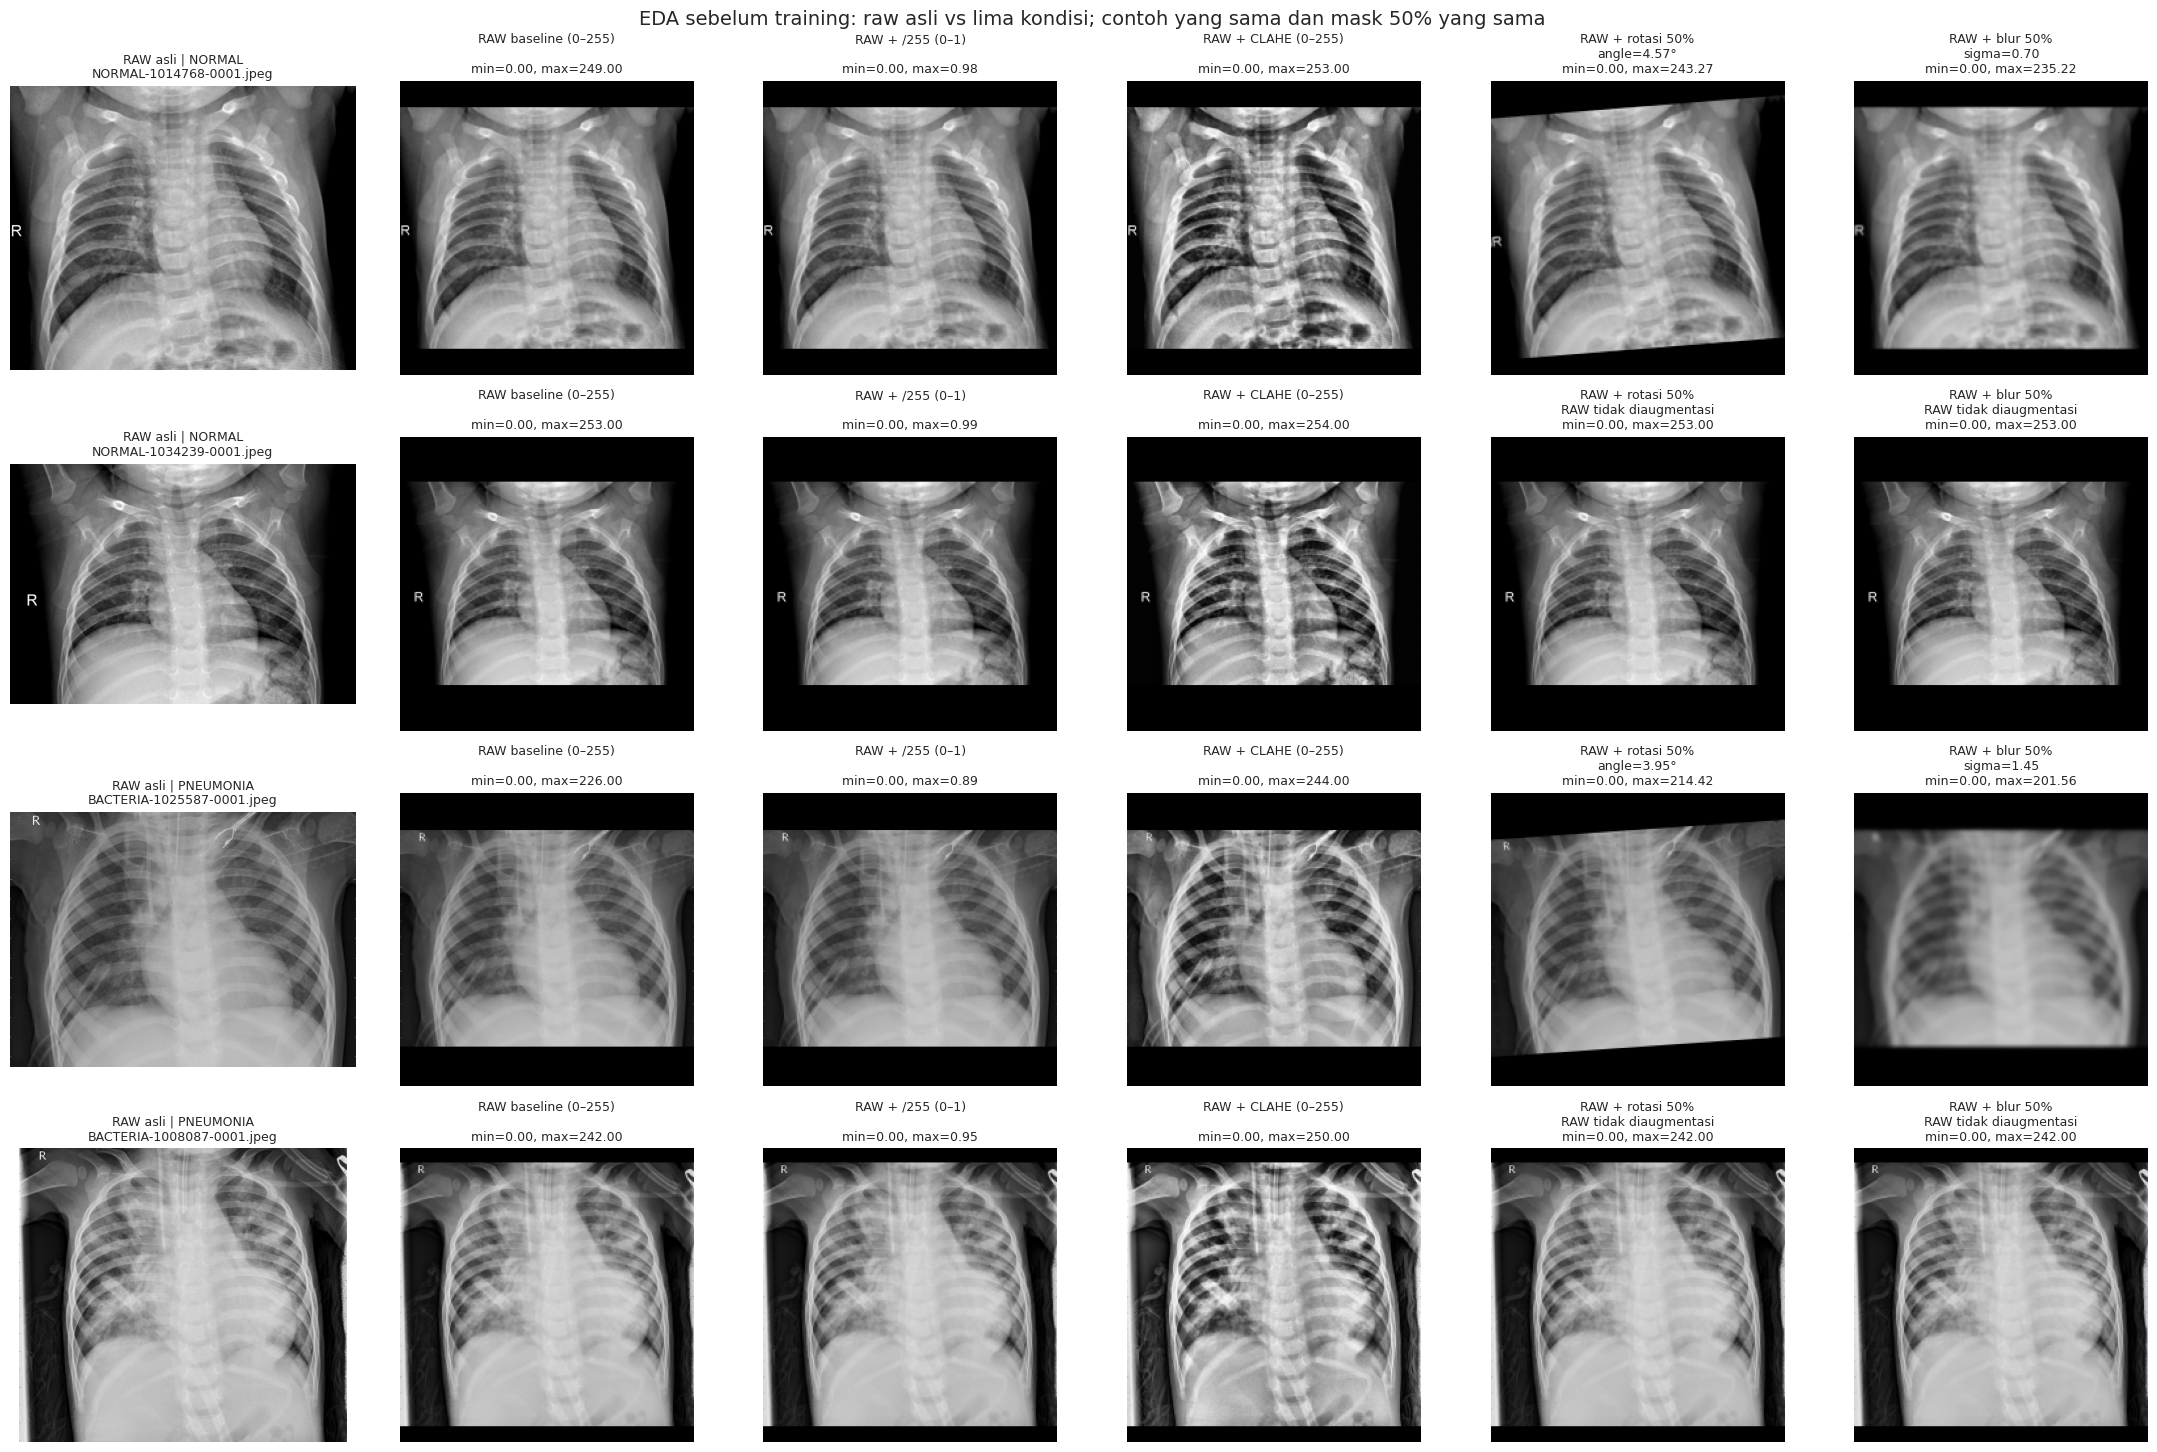

Normalisasi /255 tidak mengubah tampilan relatif citra; perubahan skala numerik ditunjukkan pada min/max dan histogram.


In [18]:
# Ambil contoh berpasangan: dua kelas x terpilih/tidak terpilih; sumber identik untuk semua kondisi.
eda_indices = []
for label in (0, 1):
    for selected in (True, False):
        candidates = np.flatnonzero((y[train_idx] == label) &
            (augmentation_plan.iloc[train_idx].selected_50pct.to_numpy() == selected))
        assert len(candidates)
        eda_indices.append(int(candidates[0]))
fig, axes = plt.subplots(len(eda_indices), 6, figsize=(22, 3.7 * len(eda_indices)), squeeze=False)
for row, local in enumerate(eda_indices):
    global_index = int(train_idx[local])
    plan = augmentation_plan.iloc[global_index]
    raw = cv2.imread(df.iloc[global_index].path, cv2.IMREAD_GRAYSCALE)
    axes[row, 0].imshow(raw, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'RAW asli | {plan.label}\n{Path(plan.path).name}', fontsize=9)
    for col, condition in enumerate(DATA_CONDITIONS, 1):
        image = modeling_data[condition]['train'][0][local]
        axes[row, col].imshow(image, cmap='gray', vmin=0, vmax=1 if condition == 'normalization' else 255)
        detail = ''
        if condition in ('rotation50', 'gaussian50'):
            detail = (f'angle={plan.rotation_degrees:.2f}°' if condition == 'rotation50'
                      else f'sigma={plan.gaussian_sigma:.2f}') if plan.selected_50pct else 'RAW tidak diaugmentasi'
        axes[row, col].set_title(f'{CONDITION_LABELS[condition]}\n{detail}\nmin={image.min():.2f}, max={image.max():.2f}', fontsize=9)
    for ax in axes[row]: ax.axis('off')
fig.suptitle('EDA sebelum training: raw asli vs lima kondisi; contoh yang sama dan mask 50% yang sama', fontsize=14)
fig.tight_layout()
fig.savefig(REPORT_OUTPUT_DIR / 'eda_raw_vs_all_conditions.png', dpi=130, bbox_inches='tight')
plt.show(); plt.close(fig)
print('Normalisasi /255 tidak mengubah tampilan relatif citra; perubahan skala numerik ditunjukkan pada min/max dan histogram.')

mean       std  min        max  \
condition     class                                            
baseline      NORMAL     100.18605  71.86730  0.0  248.41333   
              PNEUMONIA   84.13843  72.86250  0.0  231.14000   
clahe         NORMAL     100.76436  74.18302  0.0  252.84000   
              PNEUMONIA   87.46757  76.06205  0.0  245.99333   
gaussian50    NORMAL     100.19060  71.19802  0.0  242.40467   
              PNEUMONIA   84.13809  72.38904  0.0  220.46879   
normalization NORMAL       0.39289   0.28183  0.0    0.97417   
              PNEUMONIA    0.32995   0.28574  0.0    0.90643   
rotation50    NORMAL     100.40386  71.53734  0.0  246.35352   
              PNEUMONIA   84.31278  72.61125  0.0  226.30273   

                         visual_mae_vs_raw_255  
condition     class                             
baseline      NORMAL                   0.00000  
              PNEUMONIA                0.00000  
clahe         NORMAL                  17.06496  
              PNEUMONIA               13.59343  
gaussian50    NORMAL                   1.55918  
              PNEUMONIA                1.11143  
normalization NORMAL                   0.00000  
              PNEUMONIA                0.00000  
rotation50    NORMAL                  11.94907  
              PNEUMONIA                7.86748

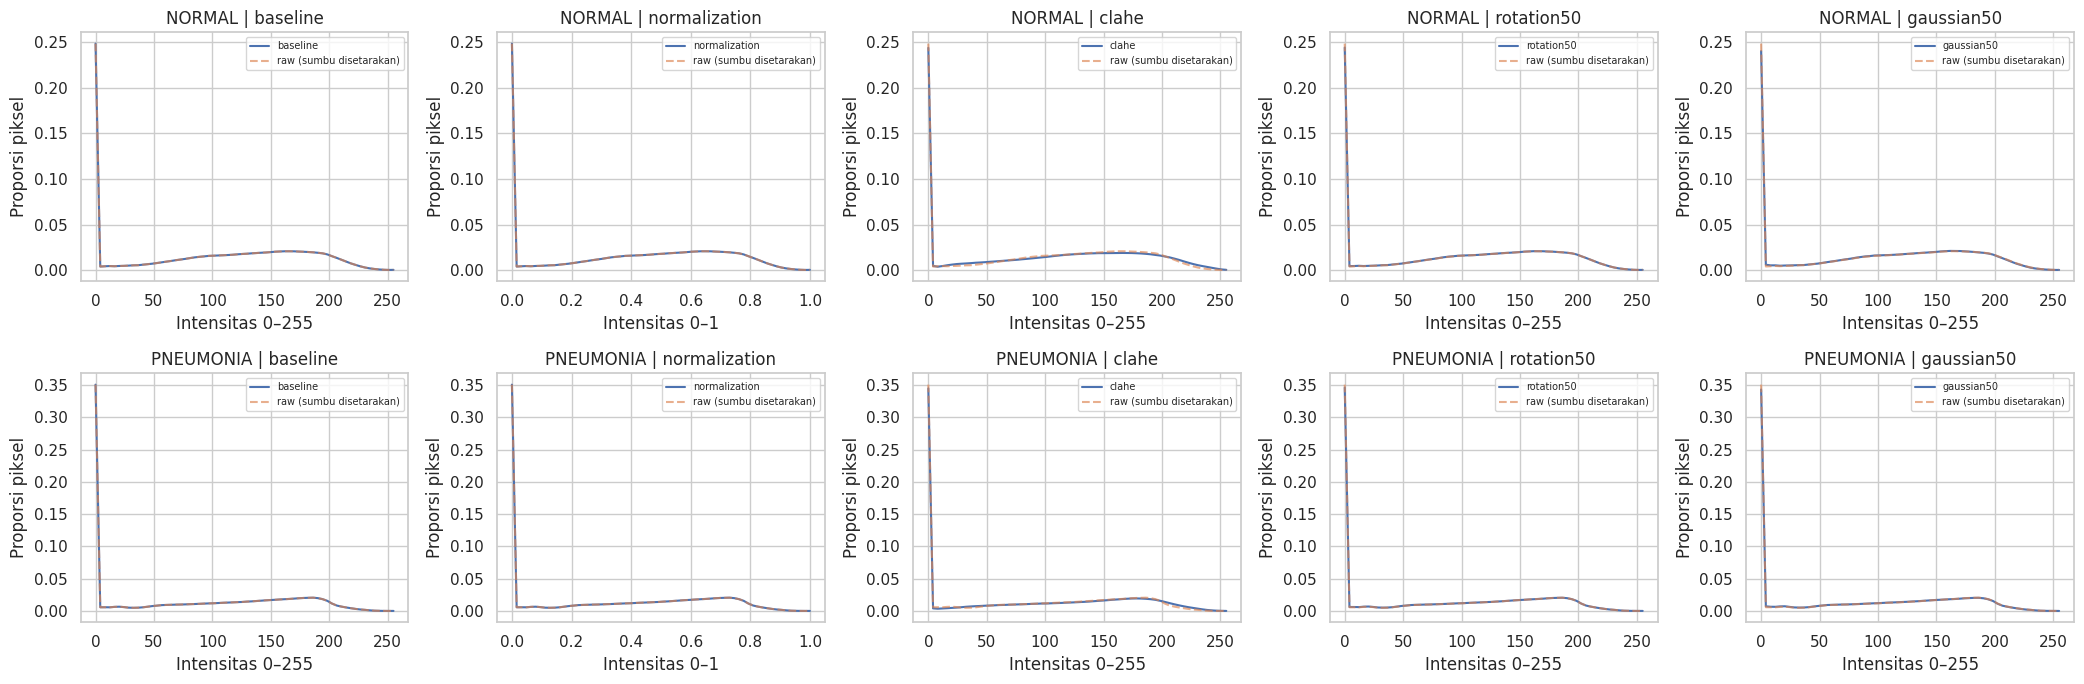

In [19]:
stats_rows, histograms = [], {}
rng = np.random.default_rng(SEED)
for label in (0, 1):
    available = np.flatnonzero(y[train_idx] == label)
    selected = np.sort(rng.choice(available, min(EDA_INTENSITY_SAMPLES, len(available)), replace=False))
    for condition in DATA_CONDITIONS:
        upper = 1. if condition == 'normalization' else 255.
        histogram = np.zeros(64)
        for local in selected:
            image = modeling_data[condition]['train'][0][int(local)]
            raw = modeling_data['baseline']['train'][0][int(local)]
            # Normalisasi balik hanya untuk selisih VISUAL; input model tetap asli kondisi masing-masing.
            visual = image * 255. if condition == 'normalization' else image
            stats_rows.append({'condition': condition, 'class': CLASS_NAMES[label],
                'source_path': df.iloc[int(train_idx[local])].path,
                'selected_50pct': bool(augmentation_plan.iloc[int(train_idx[local])].selected_50pct),
                'mean': float(image.mean()), 'std': float(image.std()),
                'min': float(image.min()), 'max': float(image.max()),
                'visual_mae_vs_raw_255': float(np.abs(visual - raw).mean())})
            histogram += np.histogram(image, bins=64, range=(0, upper))[0]
        histograms[(label, condition)] = histogram / max(histogram.sum(), 1)
eda_stats = pd.DataFrame(stats_rows)
eda_stats.to_csv(REPORT_OUTPUT_DIR / 'eda_image_statistics.csv', index=False)
display(eda_stats.groupby(['condition', 'class'])[['mean', 'std', 'min', 'max', 'visual_mae_vs_raw_255']].mean().round(5))
fig, axes = plt.subplots(2, len(DATA_CONDITIONS), figsize=(21, 7), squeeze=False)
for row, label in enumerate((0, 1)):
    for col, condition in enumerate(DATA_CONDITIONS):
        upper = 1. if condition == 'normalization' else 255.
        axis = axes[row, col]
        axis.plot(np.linspace(0, upper, 64), histograms[(label, condition)], label=condition)
        axis.plot(np.linspace(0, upper, 64), histograms[(label, 'baseline')], '--', alpha=.65, label='raw (sumbu disetarakan)')
        axis.set(title=f'{CLASS_NAMES[label]} | {condition}', xlabel=f'Intensitas 0–{upper:g}', ylabel='Proporsi piksel')
        axis.legend(fontsize=7)
fig.tight_layout(); fig.savefig(REPORT_OUTPUT_DIR / 'eda_intensity_all_conditions.png', dpi=130)
plt.show(); plt.close(fig)

In [20]:
def audit_data_conditions(bundle):
    # Sampling semua kelas dan kedua status mask; seleksi dan parameter tetap antarepoch.
    for local in eda_indices:
        raw = bundle['baseline']['train'][0][local]
        np.testing.assert_allclose(bundle['normalization']['train'][0][local], raw / 255., rtol=0, atol=0)
        selected = bool(augmentation_plan.iloc[int(train_idx[local])].selected_50pct)
        for condition in ('rotation50', 'gaussian50'):
            view = bundle[condition]['train'][0]
            np.testing.assert_array_equal(view[local], view[local])
            if not selected:
                np.testing.assert_array_equal(view[local], raw)
    for split in ('val', 'test'):
        count = len(bundle['baseline'][split][1])
        for local in range(count):
            for condition in ('rotation50', 'gaussian50'):
                np.testing.assert_array_equal(bundle[condition][split][0][local], bundle['baseline'][split][0][local])
    repeat = make_augmentation_plan(df)
    pd.testing.assert_frame_equal(augmentation_plan, repeat)
    assert not augmentation_plan.loc[augmentation_plan.orig_split != 'train', 'augmented_in_main_experiment'].any()
    return {'status': 'PASS', 'conditions': list(DATA_CONDITIONS), 'samples_per_split': EXPECTED_SPLIT_COUNTS,
        'train_augmented_per_augmentation_condition': int(len(train_idx) // 2),
        'raw_scale': '[0,255]', 'normalized_scale': '[0,1]', 'main_val_test_augmentation': False,
        'same_fixed_subset_for_rotation_and_blur': True, 'normalization_only_in_normalization_condition': True,
        'no_duplication_or_resplit': True, 'dataset_fingerprint': DATASET_FINGERPRINT}
data_audit = audit_data_conditions(modeling_data)
(REPORT_OUTPUT_DIR / 'data_audit.json').write_text(json.dumps(data_audit, indent=2), encoding='utf-8')
DATA_EDA_COMPLETED = True
print(json.dumps(data_audit, indent=2))
print('EDA SEMUA KONDISI SELESAI. Modeling baru boleh dimulai setelah sel ini.')

{
  "status": "PASS",
  "conditions": [
    "baseline",
    "normalization",
    "clahe",
    "rotation50",
    "gaussian50"
  ],
  "samples_per_split": {
    "train": 4646,
    "val": 586,
    "test": 624
  },
  "train_augmented_per_augmentation_condition": 2323,
  "raw_scale": "[0,255]",
  "normalized_scale": "[0,1]",
  "main_val_test_augmentation": false,
  "same_fixed_subset_for_rotation_and_blur": true,
  "normalization_only_in_normalization_condition": true,
  "no_duplication_or_resplit": true,
  "dataset_fingerprint": "e30b0f421eb8b1163a760a1071c868c4754bdccc82c07024b6378aa2c1674b5b"
}
EDA SEMUA KONDISI SELESAI. Modeling baru boleh dimulai setelah sel ini.


# Modeling dan protokol eksperimen <a id="modeling"></a>
Alur notebook SE dipertahankan: komponen → model → audit → loader → Weighted BCE → metrik → training/evaluasi.
Arsitektur kini selalu E5, tidak melakukan ablation E0–E6 lagi. Semua kondisi diinisialisasi ulang dengan seed sama,
tanpa warm-start antarkondisi; optimizer, weighted loss, epoch budget dan batch fisik32 tetap sama.

E5: stem → **dua residual detail 32 kanal** → empat cabang (tiga DW-separable + SE masing-masing)
→ concat → downsample → ASPP → **dua residual context 128 kanal** → **normalized learnable pooling** → classifier.
Bottleneck fusion adalah Identity. Pooling membagi weighted sum dengan sum attention (clamp minimum1e-6).
Tidak ada checkpoint lama yang ditransfer; 785.192 parameter adalah ukuran E5, bukan ukuran model SE 157.224.

In [21]:
def configure_pytorch(seed=SEED, cpu_threads=CPU_THREADS):
    if not torch.cuda.is_available():
        raise RuntimeError("GPU CUDA wajib tersedia; CPU fallback tidak diaktifkan.")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(cpu_threads)
    torch.cuda.set_device(DEVICE)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = DETERMINISTIC
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(DETERMINISTIC)
    return DEVICE


def reset_model_state(seed=SEED):
    gc.collect()
    torch.cuda.empty_cache()
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def kernel_l2(model, config=TRAIN_CONFIG):
    return config["l2"] * torch.stack([
        module.weight.square().sum() for module in model.modules()
        if isinstance(module, (nn.Conv2d, nn.Linear))
    ]).sum()


def parameter_counts(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    parameters = sum(p.numel() for p in model.parameters())
    running_statistics = sum(value.numel() for name, value in model.named_buffers()
                             if name.endswith(("running_mean", "running_var")))
    return {"parameters": parameters, "trainable_parameters": trainable,
            "bn_running_statistics": running_statistics,
            "keras_comparable_total": parameters + running_statistics}

PAPER_TEST_ACCURACY = {'PneuNet':0.91}  # Referensi historis paper, BUKAN hasil E5 ini.
REPRODUCTION_NOTES = {'architecture':'E5 from full ablation reference, fixed for five data conditions',
    'data':'baseline RAW255; /255 only normalization; CLAHE only clahe; 50% train-only rotation/blur',
    'training':'physical batch32, FP32 Adam, same weighted BCE and explicit Conv/Linear L2 as SE source',
    'test':'clean eval for rotation/blur; separate frozen-checkpoint input diagnostic',
    'clinical_validation':False}
def set_seed(seed):
    reset_model_state(seed)

In [22]:
class GrayToRGB(nn.Module):
    def forward(self, inputs):
        if inputs.ndim != 4 or inputs.shape[1] != 1:
            raise ValueError("Expected NCHW grayscale input.")
        return inputs.repeat(1, 3, 1, 1)


class SamePadConv2d(nn.Conv2d):
    """SAME padding, including asymmetric padding for stride 2."""
    def forward(self, inputs):
        height, width = inputs.shape[-2:]
        kh, kw = self.kernel_size
        sh, sw = self.stride
        dh, dw = self.dilation
        ph = max(0, (math.ceil(height / sh) - 1) * sh + dh * (kh - 1) + 1 - height)
        pw = max(0, (math.ceil(width / sw) - 1) * sw + dw * (kw - 1) + 1 - width)
        x = F.pad(inputs, (pw // 2, pw - pw // 2, ph // 2, ph - ph // 2))
        return F.conv2d(x, self.weight, self.bias, self.stride, 0, self.dilation, self.groups)


class ConvBNReLU(nn.Module):
    def __init__(self, in_channels, out_channels, kernel, stride=1, dilation=1,
                 depthwise=False, config=TRAIN_CONFIG):
        super().__init__()
        self.conv = SamePadConv2d(in_channels, out_channels, kernel, stride=stride,
                                 dilation=dilation, groups=in_channels if depthwise else 1, bias=True)
        self.bn = nn.BatchNorm2d(out_channels, eps=config["bn_eps"], momentum=config["bn_momentum"])
        self.relu = nn.ReLU(inplace=False)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.reduce = nn.Linear(channels, max(1, channels // reduction))
        self.expand = nn.Linear(max(1, channels // reduction), channels)

    def forward(self, x):
        gate = x.mean(dim=(2, 3))
        gate = torch.sigmoid(self.expand(F.relu(self.reduce(gate))))
        return x * gate[:, :, None, None]


class ConcatenateChannels(nn.Module):
    def forward(self, branches):
        return torch.cat(branches, dim=1)


class DepthwiseSeparableBlock(nn.Module):
    def __init__(self, in_channels=32, out_channels=32, config=None):
        super().__init__()

        config = TRAIN_CONFIG if config is None else config

        self.depthwise = ConvBNReLU(
            in_channels,
            in_channels,
            3,
            depthwise=True,
            config=config
        )

        self.pointwise = ConvBNReLU(
            in_channels,
            out_channels,
            1,
            config=config
        )

        # SE setelah Depthwise Separable Conv
        self.se = SEBlock(
            out_channels,
            reduction=16
        )

        self.dropout = nn.Dropout(config["dropout"])

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.se(x)
        return self.dropout(x)






class LearnableSpatialPooling(nn.Module):
    """Reconstruction hypothesis matching Table 1's 16,641 trainable weights.

    128->128 and 128->1 Conv1x1 give 16,512 + 129 parameters. The paper
    describes a single 1x1 conv and sigmoid; the extra projection is inferred.
    No BatchNorm here, because it would change the table's 16,641 count.
    """
    def __init__(self, channels=128, config=None):
        super().__init__()
        self.attention_hidden = nn.Conv2d(channels, channels, 1, bias=True)
        self.attention_activation = nn.ReLU(inplace=False)
        self.attention_conv = nn.Conv2d(channels, 1, 1, bias=True)

    def forward(self, inputs):
        attention = torch.sigmoid(self.attention_conv(
            self.attention_activation(self.attention_hidden(inputs))
        ))
        return (inputs * attention).sum(dim=(2, 3))


def initialize_pneunet(module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)

In [23]:
class PneuNet(nn.Module):
    def __init__(self, config=None):
        super().__init__()
        config = dict(TRAIN_CONFIG if config is None else config)
        self.gray_to_rgb = GrayToRGB()
        self.stem = ConvBNReLU(3, 32, 3, config=config)
        self.pointwise_branch0 = ConvBNReLU(32, 32, 1, config=config)
        self.depthwise_branches = nn.ModuleList([
            DepthwiseSeparableBlock(32, 32, config=config)
            for _ in range(3)
        ])
        self.feature_concat = ConcatenateChannels()
        
        self.downsample = nn.Sequential(
            ConvBNReLU(128, 128, 3, stride=2, depthwise=True, config=config),
            nn.Dropout(config["dropout"]),
        )
        self.aspp_1x1 = ConvBNReLU(128, 32, 1, config=config)
        self.aspp_atrous = nn.ModuleList([
            ConvBNReLU(128, 32, 3, dilation=rate, config=config) for rate in (1, 3, 6)
        ])
        self.aspp_fuse = ConvBNReLU(128, 128, 1, config=config)
        self.learnable_pooling = LearnableSpatialPooling(128, config)
        self.classifier_dropout = nn.Dropout(config["dropout"])
        self.classifier = nn.Linear(128, 1)
        self.apply(initialize_pneunet)

    def forward(self, inputs):
        stem = self.stem(self.gray_to_rgb(inputs))
        branches = [self.pointwise_branch0(stem)] + [
            branch(stem) for branch in self.depthwise_branches
        ]

        x = self.feature_concat(branches)
        x = self.downsample(x)
        x = self.aspp_fuse(torch.cat([self.aspp_1x1(x)] + [branch(x) for branch in self.aspp_atrous], dim=1))
        return self.classifier(self.classifier_dropout(self.learnable_pooling(x)))

In [24]:
class BasicResidualBlock(nn.Module):
    def __init__(self,channels,config):
        super().__init__()
        self.conv1=nn.Conv2d(channels,channels,3,stride=1,padding=1,bias=False)
        self.bn1=nn.BatchNorm2d(channels,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu1=nn.ReLU(inplace=False)
        self.conv2=nn.Conv2d(channels,channels,3,stride=1,padding=1,bias=False)
        self.bn2=nn.BatchNorm2d(channels,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu_out=nn.ReLU(inplace=False)
    def forward(self,x):
        residual=self.bn2(self.conv2(self.relu1(self.bn1(self.conv1(x)))))
        return self.relu_out(x+residual)

In [25]:
class ResidualBottleneckFusion(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.conv1=nn.Conv2d(128,32,1,bias=False)
        self.bn1=nn.BatchNorm2d(32,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu1=nn.ReLU(inplace=False)
        self.conv2=nn.Conv2d(32,32,3,stride=1,padding=1,bias=False)
        self.bn2=nn.BatchNorm2d(32,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu2=nn.ReLU(inplace=False)
        self.conv3=nn.Conv2d(32,128,1,bias=False)
        self.bn3=nn.BatchNorm2d(128,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu_out=nn.ReLU(inplace=False)
    def forward(self,x):
        residual=self.bn3(self.conv3(self.relu2(self.bn2(self.conv2(self.relu1(self.bn1(self.conv1(x))))))))
        return self.relu_out(x+residual)

In [26]:
class ConfigurableLearnableSpatialPooling(LearnableSpatialPooling):
    def __init__(self,channels=128,normalized=False,config=None):
        super().__init__(channels,config)
        self.normalized=bool(normalized)
    def attention(self,x):
        return torch.sigmoid(self.attention_conv(self.attention_activation(self.attention_hidden(x))))
    def forward(self,x):
        a=self.attention(x)
        z=(x*a).sum(dim=(2,3))
        return z/a.sum(dim=(2,3)).clamp_min(1e-6) if self.normalized else z


class PneuNetAblation(PneuNet):
    def __init__(self,experiment,config,seed):
        if experiment not in ABLATION_CONFIGS:raise ValueError(experiment)
        # All common parameters are created/initialized before optional layers.
        super().__init__(config)
        self.experiment=experiment
        self.flags=dict(ABLATION_CONFIGS[experiment])
        # Preserve freshly initialized baseline attention tensors, never trained weights.
        initial_pool=self.learnable_pooling.state_dict()
        with torch.random.fork_rng(devices=[]):
            self.learnable_pooling=ConfigurableLearnableSpatialPooling(128,self.flags["normalized"],config)
        self.learnable_pooling.load_state_dict(initial_pool,strict=True)
        self.detail_refine=nn.Sequential(*[BasicResidualBlock(32,config) for _ in range(2)]) if self.flags["detail"] else nn.Identity()
        self.bottleneck_fusion=ResidualBottleneckFusion(config) if self.flags["fusion"] else nn.Identity()
        self.context_refine=nn.Sequential(*[BasicResidualBlock(128,config) for _ in range(2)]) if self.flags["context"] else nn.Identity()
        for name in ("detail_refine","bottleneck_fusion","context_refine"):
            # Stable per-block seed; no trained weights transferred between models.
            derived=(int(seed)+int(hashlib.sha256(name.encode()).hexdigest()[:8],16))%(2**31)
            with torch.random.fork_rng(devices=[]):
                torch.manual_seed(derived)
                getattr(self,name).apply(initialize_pneunet)
    def forward(self,inputs):
        x=self.detail_refine(self.stem(self.gray_to_rgb(inputs)))
        branches=[self.pointwise_branch0(x)]+[branch(x) for branch in self.depthwise_branches]
        x=self.bottleneck_fusion(self.feature_concat(branches))
        x=self.downsample(x)
        x=self.aspp_fuse(torch.cat([self.aspp_1x1(x)]+[branch(x) for branch in self.aspp_atrous],dim=1))
        x=self.context_refine(x)
        return self.classifier(self.classifier_dropout(self.learnable_pooling(x)))


def build_ablation(experiment,seed,config=None):
    set_seed(seed)
    return PneuNetAblation(experiment,dict(TRAIN_CONFIG if config is None else config),seed)

In [27]:
def build_pneunet(config=None):
    current = dict(TRAIN_CONFIG if config is None else config)
    return build_ablation('E5', current['seed'], current)

def inspect_ablation_stages(model):
    names=["gray_to_rgb","stem.relu","detail_refine","pointwise_branch0.relu",
        *[f"depthwise_branches.{i}.se" for i in range(3)],"feature_concat","bottleneck_fusion",
        "downsample.0.relu","aspp_fuse.relu","context_refine","learnable_pooling","classifier"]
    expected={"gray_to_rgb":[1,3,224,224],"stem.relu":[1,32,224,224],
        "detail_refine":[1,32,224,224],"pointwise_branch0.relu":[1,32,224,224],
        **{f"depthwise_branches.{i}.se":[1,32,224,224] for i in range(3)},
        "feature_concat":[1,128,224,224],"bottleneck_fusion":[1,128,224,224],
        "downsample.0.relu":[1,128,112,112],"aspp_fuse.relu":[1,128,112,112],
        "context_refine":[1,128,112,112],"learnable_pooling":[1,128],"classifier":[1,1]}
    captured={"input":[1,1,224,224]};handles=[];was_training=model.training
    try:
        for name in names:
            def hook(module,args,output,name=name):captured[name]=list(output.shape)
            handles.append(model.get_submodule(name).register_forward_hook(hook))
        model.eval()
        with torch.inference_mode():logits=model(torch.zeros(1,1,224,224,device=next(model.parameters()).device))
        assert logits.shape==(1,1) and torch.isfinite(logits).all()
        for name,shape in expected.items():assert captured[name]==shape,(name,captured.get(name),shape)
        return captured
    finally:
        for h in handles:h.remove()
        model.train(was_training)


def pooling_unit_test():
    original=ConfigurableLearnableSpatialPooling(128,False)
    normalized=ConfigurableLearnableSpatialPooling(128,True)
    normalized.load_state_dict(original.state_dict(),strict=True)
    assert sum(p.numel() for p in original.parameters())==sum(p.numel() for p in normalized.parameters())==16641
    assert original.state_dict().keys()==normalized.state_dict().keys()
    x=torch.randn(2,128,5,7,requires_grad=True)
    a=original.attention(x)
    torch.testing.assert_close(a,normalized.attention(x),rtol=0,atol=0)
    torch.testing.assert_close(original(x),(x*a).sum((2,3)))
    torch.testing.assert_close(normalized(x),(x*a).sum((2,3))/a.sum((2,3)).clamp_min(1e-6))
    for pool in [original,normalized]:
        output=pool(x);assert output.shape==(2,128) and torch.isfinite(output).all()
        output.square().mean().backward(retain_graph=True)
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in pool.parameters())
    assert torch.isfinite(x.grad).all()
    for p in normalized.parameters():nn.init.zeros_(p)
    # Attention = 0.5 everywhere; explicit manual weighted mean.
    for h,w in [(5,7),(10,14)]:
        y=torch.randn(2,128,h,w,requires_grad=True)
        attention=torch.full((2,1,h,w),0.5)
        expected=(y*attention).sum((2,3))/attention.sum((2,3))
        torch.testing.assert_close(normalized(y),expected)
        torch.testing.assert_close(normalized(y),y.mean((2,3)))
    return {"status":"PASS","pooling_parameters":16641,"constant_attention_manual_mean":"PASS","gradient":"PASS"}

def inspect_pneunet_stages(model):
    return inspect_ablation_stages(model)

if RUN_ARCHITECTURE_AUDIT:
    # CPU technical audit only; no optimizer update, training, or model-performance claim.
    torch.set_num_threads(CPU_THREADS)
    audit_model = build_pneunet().cpu().eval()
    assert audit_model.flags == E5_FLAGS
    assert len(audit_model.detail_refine) == len(audit_model.context_refine) == 2
    assert isinstance(audit_model.bottleneck_fusion, nn.Identity)
    assert audit_model.learnable_pooling.normalized is True
    assert parameter_counts(audit_model)['trainable_parameters'] == 785192
    assert sum(p.numel() for p in audit_model.learnable_pooling.parameters()) == 16641
    architecture_shapes = inspect_ablation_stages(audit_model)
    pooling_audit = pooling_unit_test()
    display(pd.DataFrame([{'experiment':'E5',**E5_FLAGS,**parameter_counts(audit_model)}]))
    print('E5 architecture audit PASS',architecture_shapes,pooling_audit)
    del audit_model

,experiment,detail,fusion,context,normalized,parameters,trainable_parameters,bn_running_statistics,keras_comparable_total
0,E5,True,False,True,True,785192,785192,2560,787752


E5 architecture audit PASS {'input': [1, 1, 224, 224], 'gray_to_rgb': [1, 3, 224, 224], 'stem.relu': [1, 32, 224, 224], 'detail_refine': [1, 32, 224, 224], 'pointwise_branch0.relu': [1, 32, 224, 224], 'depthwise_branches.0.se': [1, 32, 224, 224], 'depthwise_branches.1.se': [1, 32, 224, 224], 'depthwise_branches.2.se': [1, 32, 224, 224], 'feature_concat': [1, 128, 224, 224], 'bottleneck_fusion': [1, 128, 224, 224], 'downsample.0.relu': [1, 128, 112, 112], 'aspp_fuse.relu': [1, 128, 112, 112], 'context_refine': [1, 128, 112, 112], 'learnable_pooling': [1, 128], 'classifier': [1, 1]} {'status': 'PASS', 'pooling_parameters': 16641, 'constant_attention_manual_mean': 'PASS', 'gradient': 'PASS'}


In [28]:
def build_model(model_name, config=None):
    if model_name != "PneuNet":
        raise ValueError(f"Notebook ini hanya mendukung PneuNet: {model_name}")
    return build_pneunet(config)


def build_optimizer(model, config=TRAIN_CONFIG):
    return torch.optim.Adam(model.parameters(), lr=config["learning_rate"],
                            betas=(config["beta_1"], config["beta_2"]), eps=config["epsilon"],
                            weight_decay=0.0)

In [29]:
class ModelArrayDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = np.asarray(labels, dtype=np.float32).reshape(-1, 1)
        if len(images) != len(self.labels):
            raise ValueError("Invalid image/label counts.")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = np.array(self.images[index], dtype=np.float32, copy=True)
        if image.shape != (IMG_SIZE, IMG_SIZE) or not np.isfinite(image).all() or image.min() < 0 or image.max() > 255:
            raise ValueError("Expected finite grayscale float32 input in 0-255; no implicit scaling.")
        return torch.from_numpy(image[None]), torch.from_numpy(self.labels[index].copy())

def make_loader(images, labels, batch_size, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(ModelArrayDataset(images, labels), batch_size=batch_size, shuffle=shuffle,
                      num_workers=DATALOADER_WORKERS, pin_memory=PIN_MEMORY,
                      generator=generator, drop_last=False)

def balanced_smoke_subset(images, labels, count=32):
    if count != 32:
        raise ValueError("Smoke membutuhkan 32 gambar untuk menguji batch fisik 32.")
    labels = np.asarray(labels)
    groups = [np.flatnonzero(labels == value)[:count // 2] for value in (0, 1)]
    if any(len(group) != count // 2 for group in groups):
        raise ValueError("Sampel tiap kelas tidak cukup untuk smoke.")
    indices = np.concatenate(groups)
    return np.asarray(images[indices], dtype=np.float32), labels[indices]

In [30]:
display(pd.DataFrame([{'condition':c,'split':s,'shape':str(x.shape),'dtype':str(x.dtype)}
    for c,data in modeling_data.items() for s,(x,y_values) in data.items()]))

,condition,split,shape,dtype
0,baseline,train,"(4646, 224, 224)",float32
1,baseline,val,"(586, 224, 224)",float32
2,baseline,test,"(624, 224, 224)",float32
3,normalization,train,"(4646, 224, 224)",float32
4,normalization,val,"(586, 224, 224)",float32
5,normalization,test,"(624, 224, 224)",float32
6,clahe,train,"(4646, 224, 224)",float32
7,clahe,val,"(586, 224, 224)",float32
8,clahe,test,"(624, 224, 224)",float32
9,rotation50,train,"(4646, 224, 224)",float32


## 4.1 Inverse Frequency Class Weighting dengan Weighted BCE
<a id="weighted-bce"></a>

Untuk dua kelas, bobot balanced inverse frequency dihitung sebagai

\[
w_c=\frac{N_{train}}{2n_c},\qquad
L_{data}=\frac{1}{B}\sum_{i=1}^{B}w_{y_i}\,\mathrm{BCEWithLogits}(z_i,y_i).
\]

Urutan bobot adalah **NORMAL=0, PNEUMONIA=1**. Dari 4.646 citra train (1.198 Normal dan 3.448 Pneumonia),
bobot presisinya sekitar **1,939065** dan **0,673724**. Kode menghitung ulang nilainya dari label train,
bukan membulatkan angka contoh. Bobot yang sama dipakai pada kelima kondisi dan tetap berasal dari
seluruh train ketika smoke test mengambil subset balanced 32 citra.

Implementasi menggunakan `BCEWithLogitsLoss(reduction="none")`, mengalikan tiap sampel dengan
`class_weights[targets.long()]`, kemudian mengambil **mean terhadap jumlah sampel** sesuai contoh.
Ini tidak dibagi jumlah bobot dan tidak diganti dengan `pos_weight` saja. Loss L2 yang sudah ada
ditambahkan terpisah: `loss = weighted_bce + kernel_l2`.

Validation loss memakai bobot train yang sama agar pemilihan checkpoint konsisten dengan objective
training. Accuracy, F1, ROC-AUC, confusion matrix, dan classification report tetap dihitung biasa tanpa
sample weighting pada validation/test. Tidak ada oversampling, perubahan jumlah citra, atau perubahan
threshold 0,5. Normal mendapat penalti lebih besar karena merupakan kelas minoritas; dampaknya terhadap
FP, FN dan performa harus dinilai dari full training berikutnya.

Rujukan: [scikit-learn: balanced class weight](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html)
dan [PyTorch: BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

In [31]:
def weighted_loss_config(config, train_labels):
    labels = np.asarray(train_labels).reshape(-1)
    if not len(labels) or not np.isfinite(labels).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError("Label train harus 0=NORMAL atau 1=PNEUMONIA.")
    counts = np.bincount(labels.astype(np.int64), minlength=2)
    if np.any(counts == 0):
        raise ValueError("Class weighting memerlukan kedua kelas pada data train.")
    inverse = len(labels) / (2.0 * counts.astype(np.float64))
    result = dict(config)
    enabled = bool(result.get("use_class_weighting", True))
    result.update({"class_counts": counts.astype(int).tolist(),
                   "class_weights": inverse.tolist() if enabled else [1.0, 1.0],
                   "class_weight_source": "complete_training_split_only",
                   "class_weighting": "inverse_frequency_balanced" if enabled else "none",
                   "loss_reduction": "mean_over_samples"})
    return result


def make_bce_components(config, device):
    weights = torch.tensor(config["class_weights"], dtype=torch.float32, device=device)
    if weights.shape != (2,) or not torch.isfinite(weights).all() or not (weights > 0).all():
        raise ValueError("Dibutuhkan dua class weight positif berurutan NORMAL, PNEUMONIA.")
    return nn.BCEWithLogitsLoss(reduction="none"), weights


def weighted_bce_loss(logits, targets, criterion, class_weights):
    logits = logits.reshape(-1)
    targets = targets.float().reshape(-1)
    if logits.shape != targets.shape or not ((targets == 0) | (targets == 1)).all():
        raise ValueError("Bentuk logit/target harus sama dan label harus biner.")
    loss_per_sample = criterion(logits, targets)
    sample_weights = class_weights[targets.long()]
    return (loss_per_sample * sample_weights).mean()


for condition in DATA_CONDITIONS:
    np.testing.assert_array_equal(modeling_data["baseline"]["train"][1], modeling_data[condition]["train"][1])
TRAIN_CONFIG.update(weighted_loss_config(TRAIN_CONFIG, modeling_data["baseline"]["train"][1]))
class_weight_table = pd.DataFrame({"class_id": [0, 1], "class": CLASS_NAMES,
    "train_samples": TRAIN_CONFIG["class_counts"], "weight": TRAIN_CONFIG["class_weights"]})
display(class_weight_table)
class_weight_table.to_csv(REPORT_OUTPUT_DIR / "class_weights.csv", index=False)

# Audit numerik: rumus softplus independen, pemetaan kelas, bentuk (N,1)/(N,), dan gradien.
criterion_check, weights_check = make_bce_components(TRAIN_CONFIG, DEVICE)
logits_check = torch.tensor([-1.2, 0.4, 1.7, -0.3], device=DEVICE, requires_grad=True)
targets_check = torch.tensor([0., 1., 0., 1.], device=DEVICE)
observed = weighted_bce_loss(logits_check[:, None], targets_check, criterion_check, weights_check)
expected = (torch.where(targets_check.bool(), F.softplus(-logits_check), F.softplus(logits_check))
            * weights_check[targets_check.long()]).mean()
torch.testing.assert_close(observed, expected)
torch.testing.assert_close(weighted_bce_loss(logits_check, targets_check[:, None], criterion_check,
    torch.ones_like(weights_check)), F.binary_cross_entropy_with_logits(logits_check, targets_check))
observed.backward()
assert torch.isfinite(logits_check.grad).all()
counts_check = np.asarray(TRAIN_CONFIG["class_counts"])
if USE_CLASS_WEIGHTING:
    np.testing.assert_allclose(np.asarray(TRAIN_CONFIG["class_weights"]) * counts_check,
                               np.repeat(counts_check.sum() / 2, 2), rtol=1e-12)
del logits_check, targets_check, criterion_check, weights_check, observed, expected
print("Audit Weighted BCE PASS: mean per sampel, urutan kelas, dan gradien sesuai rumus.")

,class_id,class,train_samples,weight
0,0,NORMAL,1198,1.939065
1,1,PNEUMONIA,3448,0.673724


Audit Weighted BCE PASS: mean per sampel, urutan kelas, dan gradien sesuai rumus.


## [7] Metrik evaluasi dan perbandingan model

Training penuh menyimpan accuracy, precision/recall/F1 untuk kedua kelas, macro F1, ROC-AUC, PR-AUC,
confusion matrix, probabilitas, prediksi, history, konfigurasi, dan bobot checkpoint terbaik.
Threshold tetap 0,5; model dipilih berdasarkan validation loss, bukan test.
Perbandingan memakai urutan test yang sama pada setiap model dalam satu kondisi.
McNemar dilaporkan dengan p-value exact dan chi-square continuity correction yang diberi label jelas;
angka p-value ini tidak diasumsikan identik dengan statistik pendekatan pada paper.
Smoke memeriksa fungsi evaluasi menggunakan validation kecil tetapi tidak melaporkan metriknya sebagai benchmark.

In [32]:
def binary_report(labels, probabilities, threshold=0.5):
    labels = np.asarray(labels).reshape(-1).astype(int)
    probabilities = np.asarray(probabilities).reshape(-1)
    if len(labels) != len(probabilities) or not np.isfinite(probabilities).all():
        raise ValueError("Invalid predictions.")
    predictions = (probabilities >= threshold).astype(int)
    report = classification_report(labels, predictions, labels=[0, 1],
                                   target_names=["NORMAL", "PNEUMONIA"],
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    metrics = {"accuracy": float(accuracy_score(labels, predictions)),
               "precision_pneumonia": report["PNEUMONIA"]["precision"],
               "recall_pneumonia": report["PNEUMONIA"]["recall"],
               "f1_pneumonia": report["PNEUMONIA"]["f1-score"],
               "precision_normal": report["NORMAL"]["precision"],
               "recall_normal": report["NORMAL"]["recall"],
               "f1_normal": report["NORMAL"]["f1-score"],
               "macro_f1": report["macro avg"]["f1-score"],
               "roc_auc": float(roc_auc_score(labels, probabilities)) if len(np.unique(labels)) == 2 else None,
               "pr_auc": float(average_precision_score(labels, probabilities)) if len(np.unique(labels)) == 2 else None,
               "samples": len(labels), "threshold": float(threshold)}
    return metrics, report, matrix, predictions


@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    pieces = []
    for images, _ in loader:
        logits = model(images.to(DEVICE, non_blocking=PIN_MEMORY))
        pieces.append(torch.sigmoid(logits).cpu().numpy().reshape(-1))
    return np.concatenate(pieces)


def mcnemar_comparison(labels, pneunet_predictions, comparator_predictions):
    from scipy.stats import binomtest
    labels = np.asarray(labels)
    right_p = np.asarray(pneunet_predictions) == labels
    right_c = np.asarray(comparator_predictions) == labels
    b = int(np.sum(right_p & ~right_c))
    c = int(np.sum(~right_p & right_c))
    n = b + c
    p = float(binomtest(b, n=n, p=0.5).pvalue) if n else 1.0
    return {"pneunet_only_correct": b, "comparator_only_correct": c,
            "chi2_corrected": max(0, abs(b - c) - 1) ** 2 / n if n else 0.0,
            "p_value_exact": p, "significant_0_05": p < 0.05}

## Training / smoke / full reports <a id="training"></a>
Train functions berikut disalin dari notebook asal: batch32, satu backward/update per batch, FP32,
Adam0.001, Weighted BCE train-only, L2 kernel0.001, dropout0.3, maksimum50 epoch, patience7,
checkpoint terbaik berdasarkan **validation loss**, threshold evaluasi tetap0.5.
Mode smoke tidak melakukan inferensi test. Full report hanya memakai hasil baru E5 yang lengkap untuk lima kondisi.
Set `RUN_TRAINING=True` dan `MODELING_RUN_MODE='full'` di konfigurasi jika ingin memulai full training.
Jangan menjalankan full pada GPU yang sedang dipakai eksperimen lain tanpa mengecek kapasitas.

In [33]:
def initial_weight_fingerprint(model):
    digest = hashlib.sha256()
    for name, value in model.state_dict().items():
        digest.update(name.encode("utf-8"))
        digest.update(value.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


def load_checkpoint(model, checkpoint):
    payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
    if payload.get("architecture_version") != ARCH_VERSION:
        raise ValueError("Checkpoint bukan E5 data-ablation notebook ini.")
    model.load_state_dict(payload["state_dict"], strict=True)
    return {key: value for key, value in payload.items() if key != "state_dict"}


def train_one_epoch(model, loader, optimizer, config, max_batches=None):
    model.train()
    criterion, class_weights = make_bce_components(config, DEVICE)
    total_loss, total_samples, updates = 0.0, 0, 0
    actual, probabilities = [], []
    for batch_index, (images, labels) in enumerate(loader):
        if max_batches is not None and batch_index >= max_batches:
            break
        optimizer.zero_grad(set_to_none=True)
        x = images.to(DEVICE, non_blocking=PIN_MEMORY)
        y = labels.to(DEVICE, non_blocking=PIN_MEMORY)
        logits = model(x)
        loss = weighted_bce_loss(logits, y, criterion, class_weights) + kernel_l2(model, config)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")
        loss.backward()
        if max_batches is not None:
            for name, parameter in model.named_parameters():
                if parameter.grad is not None and not torch.isfinite(parameter.grad).all():
                    raise RuntimeError(f"Non-finite gradient: {name}")
        optimizer.step()
        updates += 1
        total_loss += float(loss.detach()) * len(y)
        total_samples += len(y)
        actual.extend(y.detach().cpu().numpy().reshape(-1))
        probabilities.extend(torch.sigmoid(logits.detach()).cpu().numpy().reshape(-1))
    if not total_samples:
        raise RuntimeError("Empty training loader.")
    metrics, _, _, _ = binary_report(actual, probabilities, config["threshold"])
    return {"loss": total_loss / total_samples, "accuracy": metrics["accuracy"],
            "roc_auc": metrics["roc_auc"]}, updates



@torch.inference_mode()
def validate_one_epoch(model, loader, config, max_batches=None):
    model.eval()
    criterion, class_weights = make_bce_components(config, DEVICE)
    total_loss, count, actual, probabilities = 0.0, 0, [], []
    penalty = float(kernel_l2(model, config))
    for index, (images, labels) in enumerate(loader):
        if max_batches is not None and index >= max_batches:
            break
        x, y = images.to(DEVICE, non_blocking=PIN_MEMORY), labels.to(DEVICE, non_blocking=PIN_MEMORY)
        logits = model(x)
        loss = float(weighted_bce_loss(logits, y, criterion, class_weights)) + penalty
        if not np.isfinite(loss):
            raise RuntimeError("Non-finite validation loss.")
        total_loss += loss * len(y)
        count += len(y)
        actual.extend(y.cpu().numpy().reshape(-1))
        probabilities.extend(torch.sigmoid(logits).cpu().numpy().reshape(-1))
    metrics, _, _, _ = binary_report(actual, probabilities, config["threshold"])
    return {"val_loss": total_loss / count, "val_accuracy": metrics["accuracy"], "val_roc_auc": metrics["roc_auc"]}


def run_experiment(model_name, condition, bundle, output_root, mode="smoke", config=None):
    if mode not in ("smoke", "full") or model_name not in MODEL_NAMES or condition not in DATA_CONDITIONS:
        raise ValueError("Invalid experiment configuration.")
    config = weighted_loss_config(TRAIN_CONFIG if config is None else config, bundle["baseline"]["train"][1])
    if config["initial_weights"] is not None or config["batch_size"] != 32:
        raise ValueError("Use random initialization and a physical batch size of 32.")
    if mode == "smoke" and (SMOKE_CONFIG != {"train_samples": 32, "validation_samples": 32, "batch_size": 32,
                                           "epochs": 1, "steps_per_epoch": 1, "validation_steps": 1}):
        raise ValueError("Smoke limits must remain 32 samples, one epoch, one update.")
    reset_model_state(config["seed"])
    directory = Path(output_root) / f"{model_name}__{condition}"
    directory.mkdir(parents=True, exist_ok=True)
    data = bundle[condition]
    if mode == "smoke":
        train_x, train_y = balanced_smoke_subset(*data["train"], SMOKE_CONFIG["train_samples"])
        val_x, val_y = balanced_smoke_subset(*data["val"], SMOKE_CONFIG["validation_samples"])
        batch_size, epochs = SMOKE_CONFIG["batch_size"], SMOKE_CONFIG["epochs"]
    else:
        train_x, train_y = data["train"]
        val_x, val_y = data["val"]
        batch_size, epochs = config["batch_size"], config["epochs"]
    train_loader = make_loader(train_x, train_y, batch_size, shuffle=True, seed=config["seed"])
    inference_batch = batch_size
    val_loader = make_loader(val_x, val_y, inference_batch)
    model = build_model(model_name, config).to(DEVICE)
    optimizer = build_optimizer(model, config)
    if next(model.parameters()).device.type != "cuda":
        raise RuntimeError("Model must run on CUDA.")
    torch.cuda.reset_peak_memory_stats(DEVICE)
    metadata = {"model": model_name, "condition": condition, "mode": mode,
                "framework": "pytorch", "architecture_version": ARCH_VERSION, "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
                "python": sys.executable, "device": str(DEVICE), "gpu": torch.cuda.get_device_name(DEVICE),
                "cuda_build": torch.version.cuda, "precision": "float32", **parameter_counts(model),
                "config": config, "effective_batch_size": batch_size,
                "physical_batch_size": batch_size, "gradient_accumulation_steps": 1, "effective_epochs": epochs,
                "training_samples": len(train_y), "validation_samples": len(val_y),
                "initial_weight_sha256": initial_weight_fingerprint(model), "test_evaluated": False,
                "purpose": "error_detection_only" if mode == "smoke" else "performance_evaluation",
                "reproduction_notes": REPRODUCTION_NOTES, "loss_version": config["loss_version"],
                "class_weights": config["class_weights"], "class_counts": config["class_counts"],
                "class_weight_source": config["class_weight_source"]}
    if model_name == "PneuNet":
        metadata["stage_shapes_NCHW"] = inspect_pneunet_stages(model)
    metadata.update({'experiment':'E5','architecture_flags':dict(E5_FLAGS),
        'dataset_fingerprint':DATASET_FINGERPRINT,'data_condition_label':CONDITION_LABELS[condition],
        'normalization_applied':condition=='normalization','augmentation_fraction_train':.5 if condition in ('rotation50','gaussian50') else 0.,
        'augmentation_assignment':str(REPORT_OUTPUT_DIR/'augmentation_assignment.csv'),
        'main_test_augmented':False})
    (directory / "architecture.txt").write_text(str(model) + chr(10) + json.dumps(parameter_counts(model)), encoding="utf-8")
    (directory / "architecture.json").write_text(json.dumps({"model": model_name, "config": config,
            "parameters": parameter_counts(model)}, indent=2), encoding="utf-8")
    checkpoint = directory / "best.pt"
    rows, best_loss, best_epoch, stale, updates = [], float("inf"), None, 0, 0
    start = time.perf_counter()
    try:
        for epoch in range(epochs):
            train_stats, epoch_updates = train_one_epoch(model, train_loader, optimizer, config,
                                                          max_batches=1 if mode == "smoke" else None)
            validation = validate_one_epoch(model, val_loader, config, max_batches=1 if mode == "smoke" else None)
            updates += epoch_updates
            row = {"epoch": epoch, **train_stats, **validation}
            rows.append(row)
            pd.DataFrame(rows).to_csv(directory / f"{mode}_history.csv", index=False)
            if validation["val_loss"] < best_loss:
                best_loss, best_epoch, stale = validation["val_loss"], epoch + 1, 0
                torch.save({"state_dict": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
                            "config": config, "epoch": best_epoch, "model": model_name, "condition": condition,
                             "architecture_version": ARCH_VERSION, "loss_version": config["loss_version"]}, checkpoint)
            else:
                stale += 1
            if mode == "full":
                print(f"  epoch {epoch + 1}/{epochs}: loss={row['loss']:.5f}, val_loss={row['val_loss']:.5f}", flush=True)
            if stale >= config["early_stopping_patience"]:
                break
        torch.cuda.synchronize(DEVICE)
        metadata.update({"seconds": time.perf_counter() - start, "epochs_completed": len(rows),
                         "optimizer_updates": updates, "best_epoch": best_epoch,
                         "gpu_peak_allocated_mb": torch.cuda.max_memory_allocated(DEVICE) / 1024**2})
        if not checkpoint.is_file():
            raise RuntimeError("Best checkpoint was not saved.")
        load_checkpoint(model, checkpoint)
        probabilities = predict_loader(model, val_loader)
        if not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
            raise RuntimeError("Invalid sigmoid predictions.")
        for name, weight in model.state_dict().items():
            if not torch.isfinite(weight).all():
                raise RuntimeError(f"Non-finite model state: {name}")
        if mode == "smoke":
            assert updates == len(rows) == 1 and len(train_y) == len(val_y) == 32
            binary_report(val_y, probabilities, config["threshold"])
            with torch.no_grad():
                model.classifier.weight.zero_()
            load_checkpoint(model, checkpoint)
            np.testing.assert_allclose(predict_loader(model, val_loader), probabilities, rtol=1e-5, atol=1e-6)
            metadata.update({"finite_training_loss": True, "finite_validation_loss": True,
                             "checkpoint_reload_passed": True, "status": "PASS"})
        else:
            for split in ("train", "val", "test"):
                images, labels = data[split]
                probability = predict_loader(model, make_loader(images, labels, inference_batch))
                metrics, report, matrix, predictions = binary_report(labels, probability, config["threshold"])
                metadata[f"{split}_metrics"] = metrics
                (directory / f"{split}_classification_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
                pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(directory / f"{split}_confusion_matrix.csv")
                prediction_table = pd.DataFrame({"source_index": np.arange(len(labels)), "y_true": labels,
                                                 "probability": probability, "prediction": predictions})
                current_source = globals().get("df")
                if current_source is not None:
                    split_source = current_source.loc[current_source.orig_split == split].reset_index(drop=True)
                    np.testing.assert_array_equal(split_source.y.to_numpy(), labels)
                    prediction_table["source_path"] = split_source.path.to_numpy()
                prediction_table.to_csv(directory / f"{split}_predictions.csv", index=False)
            metadata.update({"test_evaluated": True, "status": "COMPLETE"})
        (directory / "result.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
        return metadata
    finally:
        del model, optimizer
        reset_model_state(config["seed"])

In [34]:
def summarize_runs(results, output_root, mode):
    rows = []
    for result in results:
        row = {key: result[key] for key in ("model", "condition", "mode", "status", "parameters", "trainable_parameters", "optimizer_updates", "seconds", "device", "gpu", "gpu_peak_allocated_mb")}
        if mode == "full":
            row.update(result["test_metrics"])
            row["paper_test_accuracy_reference_only"] = PAPER_TEST_ACCURACY[result["model"]]
        else:
            row.update({"test_evaluated": result["test_evaluated"],
                        "checkpoint_reload_passed": result["checkpoint_reload_passed"]})
        rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(Path(output_root) / f"{mode}_summary.csv", index=False)
    return table


def full_comparison_artifacts(results, bundle, output_root):
    """Called only by the full mode; never by the smoke test."""
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, precision_recall_curve
    output_root = Path(output_root)
    mcnemar_rows = []
    for condition in DATA_CONDITIONS:
        available = [r for r in results if r["condition"] == condition]
        if not available:
            continue
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
        test_labels = bundle[condition]["test"][1]
        pneunet = next((r for r in available if r["model"] == "PneuNet"), None)
        p_predictions = None
        if pneunet:
            p_predictions = pd.read_csv(output_root / f"PneuNet__{condition}" / "test_predictions.csv")["prediction"].to_numpy()
        for result in available:
            name = result["model"]
            directory = output_root / f"{name}__{condition}"
            frame = pd.read_csv(directory / "test_predictions.csv")
            np.testing.assert_array_equal(frame["y_true"].to_numpy(), test_labels)
            fpr, tpr, _ = roc_curve(test_labels, frame["probability"])
            precision, recall, _ = precision_recall_curve(test_labels, frame["probability"])
            axes[0].plot(fpr, tpr, label=name)
            axes[1].plot(recall, precision, label=name)
            history = pd.read_csv(directory / "full_history.csv")
            axes[2].plot(history["epoch"] + 1, history["val_loss"], label=name)
            fig_history, history_axes = plt.subplots(1, 2, figsize=(10, 4))
            for key, axis in [("accuracy", history_axes[0]), ("loss", history_axes[1])]:
                axis.plot(history["epoch"] + 1, history[key], label="train")
                axis.plot(history["epoch"] + 1, history[f"val_{key}"], label="validation")
                axis.set(xlabel="Epoch", ylabel=key, title=f"{name} / {condition}")
                axis.legend()
            fig_history.tight_layout()
            fig_history.savefig(directory / "training_curves.png", dpi=150)
            plt.close(fig_history)
            if p_predictions is not None and name != "PneuNet":
                mcnemar_rows.append({"condition": condition, "comparator": name,
                    **mcnemar_comparison(test_labels, p_predictions, frame["prediction"].to_numpy())})
            fig_cm, ax = plt.subplots(figsize=(4, 4))
            matrix = confusion_matrix(test_labels, frame["prediction"], labels=[0, 1])
            ax.imshow(matrix, cmap="Blues")
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, str(matrix[i, j]), ha="center", va="center")
            ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["NORMAL", "PNEUMONIA"],
                   yticklabels=["NORMAL", "PNEUMONIA"], xlabel="Prediction", ylabel="True label", title=f"{name} / {condition}")
            fig_cm.tight_layout()
            fig_cm.savefig(directory / "test_confusion_matrix.png", dpi=150)
            plt.close(fig_cm)
        for ax, title in zip(axes, ["Test ROC", "Test precision-recall", "Validation loss"]):
            ax.set_title(title)
            ax.legend(fontsize=7)
        axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
        axes[1].set(xlabel="Recall", ylabel="Precision")
        axes[2].set(xlabel="Epoch", ylabel="Weighted BCE validation loss (including L2)")
        fig.tight_layout()
        fig.savefig(output_root / f"full_comparison_{condition}.png", dpi=150)
        plt.close(fig)
    if mcnemar_rows:
        pd.DataFrame(mcnemar_rows).to_csv(output_root / "mcnemar_exact_tests.csv", index=False)
    summary = summarize_runs(results, output_root, "full")
    if len(summary):
        baseline_row = summary.loc[summary.condition == 'baseline'].iloc[0]
        deltas = summary[['model','condition','accuracy','macro_f1']].copy()
        deltas['accuracy_delta_vs_raw'] = deltas.accuracy - baseline_row.accuracy
        deltas['macro_f1_delta_vs_raw'] = deltas.macro_f1 - baseline_row.macro_f1
        deltas.to_csv(output_root / 'full_ablation_deltas_vs_raw.csv', index=False)



def run_modeling_suite(workspace, mode="smoke", model_names=MODEL_NAMES,
                       conditions=DATA_CONDITIONS, namespace=None, output_root=None):
    if mode not in ("smoke", "full"):
        raise ValueError("mode must be 'smoke' or 'full'")
    workspace = Path(workspace)
    configure_pytorch(TRAIN_CONFIG["seed"])
    bundle = resolve_modeling_data(workspace, namespace)
    output_root = Path(output_root) if output_root else MODELING_RESULTS_ROOT / f"pytorch_{mode}_{ARCH_VERSION}_{LOSS_VERSION}_{datetime.now():%Y%m%d_%H%M%S}"
    output_root.mkdir(parents=True, exist_ok=False)
    results = []
    for name in model_names:
        for condition in conditions:
            print(f"{mode.upper()}: {name} / {condition}", flush=True)
            result = run_experiment(name, condition, bundle, output_root, mode)
            results.append(result)
            summarize_runs(results, output_root, mode)
            print(f"  {result['status']}; updates={result['optimizer_updates']}; test_evaluated={result['test_evaluated']}", flush=True)
    table = summarize_runs(results, output_root, mode)
    fingerprints = {r['initial_weight_sha256'] for r in results}
    assert len(fingerprints) == 1, 'Kondisi tidak mulai dari bobot identik.'
    if mode == "full":
        full_comparison_artifacts(results, bundle, output_root)
    print("Results:", output_root)
    return table, output_root

In [35]:
def saved_experiment_records(run_dir=None):
    run_dir = resolve_saved_run_dir(
        SAVED_RUN_DIR if run_dir is None else run_dir,
        MODEL_NAMES, DATA_CONDITIONS, globals().get("ARCH_VERSION"))
    if run_dir is None:
        print("Laporan dilewati: belum ada run full lengkap di folder modeling notebook ini.")
        return []
    records = []
    for model_name in MODEL_NAMES:
        for condition in DATA_CONDITIONS:
            directory = run_dir / f"{model_name}__{condition}"
            info = json.loads((directory / "result.json").read_text(encoding="utf-8"))
            if info.get("mode") != "full" or info.get("status") != "COMPLETE" or not info.get("test_evaluated"):
                raise ValueError(f"Hasil full belum lengkap: {directory}")
            if info["model"] != model_name or info["condition"] != condition:
                raise ValueError(f"Model/kondisi tidak cocok: {directory}")
            expected_version = globals().get("ARCH_VERSION")
            if expected_version is not None and info.get("architecture_version") != expected_version:
                raise ValueError(f"Versi arsitektur checkpoint berbeda: {directory}")
            history = pd.read_csv(directory / "full_history.csv")
            required = {"epoch", "loss", "val_loss"}
            if not required.issubset(history.columns) or history.empty:
                raise ValueError(f"History tidak lengkap: {directory}")
            if not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
                raise ValueError(f"Loss non-finite: {directory}")
            prediction = pd.read_csv(directory / "test_predictions.csv")
            metrics, _, _, _ = binary_report(prediction.y_true, prediction.probability, info["config"]["threshold"])
            for key in ("accuracy", "macro_f1", "recall_normal", "recall_pneumonia"):
                np.testing.assert_allclose(metrics[key], info["test_metrics"][key], atol=1e-10)
            records.append({"directory": directory, "info": info, "history": history, "prediction": prediction})
    return records


def saved_results_table(records):
    rows = []
    for record in records:
        info = record["info"]
        rows.append({"Model": info["model"], "Kondisi": info["condition"],
                     "Loss": "Weighted BCE" if info["config"].get("use_class_weighting", False) else "BCE referensi",
                     "Accuracy (%)": 100 * info["test_metrics"]["accuracy"],
                     "Macro-F1": info["test_metrics"]["macro_f1"],
                     "ROC-AUC": info["test_metrics"]["roc_auc"],
                     "Recall NORMAL": info["test_metrics"]["recall_normal"],
                     "Recall PNEUMONIA": info["test_metrics"]["recall_pneumonia"],
                     "Epoch terbaik": info.get("best_epoch"), "Epoch selesai": info.get("epochs_completed"),
                     "Parameter": info["trainable_parameters"]})
    table = pd.DataFrame(rows)
    table.to_csv(REPORT_OUTPUT_DIR / "saved_results_summary.csv", index=False)
    return table


def display_saved_loss_curves(records):
    files = []
    for model_name in MODEL_NAMES:
        selected = [record for record in records if record["info"]["model"] == model_name]
        if not selected:
            continue
        fig, axes = plt.subplots(2, len(selected), figsize=(6.7 * len(selected), 7.8), squeeze=False)
        for column, record in enumerate(selected):
            history, info = record["history"], record["info"]
            epochs = history["epoch"].to_numpy() + 1
            for row in range(2):
                axis = axes[row, column]
                axis.plot(epochs, history["loss"], label="Train loss", color="#2563eb", linewidth=1.8)
                axis.plot(epochs, history["val_loss"], label="Validation loss", color="#dc2626", linewidth=1.8)
                if info.get("best_epoch") is not None:
                    axis.axvline(info["best_epoch"], color="#64748b", linestyle="--", alpha=0.7,
                                 label=f"Checkpoint epoch {info['best_epoch']}")
                loss_label = "Weighted BCE + L2 loss" if info["config"].get("use_class_weighting", False) else "BCE + L2 loss (referensi)"
                axis.set(xlabel="Epoch", ylabel=loss_label, title=f"{info['condition']} | {'linear' if row == 0 else 'detail log'}")
                if row == 1:
                    if (history[["loss", "val_loss"]].to_numpy() > 0).all():
                        axis.set_yscale("log")
                    else:
                        axis.set_yscale("symlog", linthresh=0.01)
                axis.legend(fontsize=8)
                axis.grid(alpha=0.25)
        fig.suptitle(f"{model_name}: loss dari history training tersimpan", fontsize=14)
        fig.tight_layout(rect=(0, 0, 1, 0.96))
        destination = REPORT_OUTPUT_DIR / f"{model_name}_train_validation_loss.png"
        fig.savefig(destination, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        files.append(str(destination))
    return files


def display_saved_benchmark():
    if globals().get("modeling_output_dir") is None:
        print("Benchmark latency dilewati: belum ada run full yang dipilih.")
        return
    file = Path(modeling_output_dir) / "test_inference_accuracy_f1_latency_batch1.csv"
    if file.is_file():
        display(pd.read_csv(file).round(4))
    else:
        print("Benchmark latency tidak tersedia pada run ini; tidak dihitung ulang.")

In [36]:
saved_records = []
training_output_dir = None
if RUN_TRAINING:
    training_summary, training_output_dir = run_modeling_suite(
        MODELING_WORKSPACE, mode=MODELING_RUN_MODE, model_names=SELECTED_MODELS,
        conditions=SELECTED_CONDITIONS, namespace=globals())
    display(training_summary)
modeling_output_dir = resolve_saved_run_dir(SAVED_RUN_DIR, MODEL_NAMES, DATA_CONDITIONS, ARCH_VERSION)
if modeling_output_dir is not None:
    saved_records = saved_experiment_records(modeling_output_dir)
    for record in saved_records:
        assert record['info'].get('dataset_fingerprint') == DATASET_FINGERPRINT
    display(saved_results_table(saved_records))
    loss_plot_files = display_saved_loss_curves(saved_records)
else:
    loss_plot_files = []
    print('Belum ada full run lima kondisi baru. EDA/audit tersedia; tidak memuat metrik atau checkpoint eksperimen lama.')

Belum ada full run lima kondisi baru. EDA/audit tersedia; tidak memuat metrik atau checkpoint eksperimen lama.


# Confusion matrix dan classification report <a id="classification-reports"></a>
Seluruh lima kondisi × train/validation/test. Data dari CSV full run baru, diverifikasi dengan label dan path asli.
Tidak ada classification report test dari smoke atau pemuatan hasil SE/E0–E6 lama.

In [37]:
def show_all_classification_reports(records):
    summary = []
    for split in CLASSIFICATION_REPORT_SPLITS:
        fig, axes = plt.subplots(1, len(records), figsize=(5 * len(records), 4), squeeze=False)
        for col, record in enumerate(records):
            condition = record['info']['condition']
            frame = pd.read_csv(record['directory'] / f'{split}_predictions.csv')
            expected = df.loc[df.orig_split == split].reset_index(drop=True)
            assert frame.source_path.is_unique
            np.testing.assert_array_equal(frame.source_path.astype(str), expected.path.astype(str))
            np.testing.assert_array_equal(frame.y_true, expected.y)
            metrics, report, matrix, predictions = binary_report(frame.y_true, frame.probability)
            np.testing.assert_array_equal(predictions, frame.prediction)
            display(pd.DataFrame(report).T.round(4).rename_axis(f'{condition}/{split}'))
            axis = axes[0, col]
            sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axis)
            axis.set(title=f'{condition} / {split}', xlabel='Prediksi', ylabel='Label asli')
            summary.append({'condition': condition, 'split': split, **metrics})
        fig.tight_layout()
        fig.savefig(REPORT_OUTPUT_DIR / f'confusion_matrices_{split}_all_conditions.png', dpi=130)
        plt.show(); plt.close(fig)
    table = pd.DataFrame(summary)
    table.to_csv(REPORT_OUTPUT_DIR / 'all_split_classification_metrics.csv', index=False)
    return table


classification_summary = pd.DataFrame()
if saved_records:
    classification_summary = show_all_classification_reports(saved_records)
    display(classification_summary)
else:
    print('Classification report menunggu full run lima kondisi yang lengkap; tidak menyalin hasil notebook asal.')

Classification report menunggu full run lima kondisi yang lengkap; tidak menyalin hasil notebook asal.


# Analisis kesalahan dan Grad-CAM <a id="gradcam"></a>
Seperti notebook asal, tampilkan contoh NORMAL/PNEUMONIA dan heatmap kedua kelas untuk setiap kondisi.
Target layer E5 adalah `context_refine.1.relu_out`, sebelum normalized pooling.
Input model tidak dinormalisasi tersembunyi; pembagian untuk tampilan saja tidak mengubah inferensi.
Heatmap bukan bukti kausal atau validasi klinis. Galeri hanya tersedia setelah checkpoint full baru ada.

In [38]:
def display_image(image):
    image = np.asarray(image,dtype=np.float32)
    return image / 255. if image.size and image.max() > 1 else image

def select_error_examples(table, maximum=ERROR_ANALYSIS_MAX_CASES):
    # Ambil FP/FN bergantian agar galeri tidak didominasi satu jenis kesalahan.
    queues = [table.loc[table.error_type == kind].sort_values("prediction_confidence", ascending=False)
              for kind in ("FP", "FN")]
    chosen = []
    for position in range(max(len(queue) for queue in queues)):
        for queue in queues:
            if position < len(queue) and len(chosen) < maximum:
                chosen.append(queue.index[position])
    if chosen:
        return table.loc[chosen].copy()
    return table.sort_values("prediction_confidence", ascending=False).head(maximum).copy()

In [39]:
from matplotlib.colors import LinearSegmentedColormap


def make_gradcam_components(model, model_name):
    target_name = GRADCAM_TARGET_LAYERS[model_name]
    model.get_submodule(target_name)
    return {"model": model, "target_layer": target_name}


def gradcam_heatmap(image, components, class_id):
    if class_id not in (0, 1):
        raise ValueError("Target must be NORMAL=0 or PNEUMONIA=1.")
    image = np.asarray(image, dtype=np.float32)
    if image.shape != (IMG_SIZE, IMG_SIZE) or not np.isfinite(image).all() or image.min() < 0 or image.max() > 255:
        raise ValueError("Expected finite grayscale input in 0-255.")
    model = components["model"]
    target = model.get_submodule(components["target_layer"])
    batch = torch.from_numpy(image.copy()[None, None]).to(DEVICE)
    was_training = model.training
    parameter_flags = [parameter.requires_grad for parameter in model.parameters()]
    captured = {}
    def capture(module, inputs, output):
        activation = output.detach().requires_grad_(True)
        captured["activation"] = activation
        return activation
    handle = None
    try:
        model.eval()
        for parameter in model.parameters():
            parameter.requires_grad_(False)
        handle = target.register_forward_hook(capture)
        with torch.enable_grad():
            logits = model(batch)
            score = (logits if class_id == 1 else -logits).sum()
            features = captured["activation"]
            gradients = torch.autograd.grad(score, features, retain_graph=False)[0]
            if not torch.isfinite(gradients).all():
                raise RuntimeError("Non-finite Grad-CAM gradients.")
            weights = gradients.mean(dim=(2, 3), keepdim=True)
            heatmap = F.relu((features.detach() * weights).sum(dim=1, keepdim=True))
            maximum = heatmap.amax(dim=(2, 3), keepdim=True)
            heatmap = heatmap / maximum.clamp_min(torch.finfo(heatmap.dtype).tiny)
            heatmap = F.interpolate(heatmap, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
            heatmap = heatmap[0, 0].detach().cpu().numpy()
            probability = float(torch.sigmoid(logits.detach())[0, 0])
        handle.remove()
        handle = None
        with torch.inference_mode():
            original_probability = float(torch.sigmoid(model(batch))[0, 0])
        np.testing.assert_allclose(probability, original_probability, rtol=1e-4, atol=1e-6)
        if heatmap.shape != image.shape or not np.isfinite(heatmap).all():
            raise RuntimeError("Invalid Grad-CAM heatmap.")
        return heatmap, probability
    finally:
        if handle is not None:
            handle.remove()
        for parameter, flag in zip(model.parameters(), parameter_flags):
            parameter.requires_grad_(flag)
        model.train(was_training)



def display_gradcam_examples(table, images, components, destination, mode):
    selected = select_error_examples(table)
    count = len(selected)

    if not count:
        raise ValueError("Tidak ada citra untuk Grad-CAM.")

    paper_cmap = LinearSegmentedColormap.from_list(
        "paper_cam",
        [
            "#182079",
            "#2f3eae",
            "#456cca",
            "#27b5b6",
            "#f2d76a",
            "#ed5144"
        ]
    )

    fig, axes = plt.subplots(
        count, 3,
        figsize=(16, 4.5 * count),
        squeeze=False
    )

    output_rows = []

    for row, (_, case) in enumerate(selected.iterrows()):
        image = np.asarray(
            images[int(case.source_index)],
            dtype=np.float32
        )

        heatmap, probability = gradcam_heatmap(
            image, components, int(case.prediction)
        )

        np.testing.assert_allclose(
            probability, case.probability,
            rtol=1e-4, atol=1e-6
        )

        zero_map = bool(np.max(heatmap) == 0)

        label = (
            f"{case.error_type} | "
            f"true={case.true_label}, "
            f"pred={case.predicted_label}"
        )

        # Kolom 1: Original Image
        axes[row, 0].imshow(
            display_image(image), cmap="gray", vmin=0, vmax=1
        )
        axes[row, 0].set_title(
            label + f"\np(pneumonia)={probability:.4f}",
            fontsize=10
        )

        # Kolom 2: Grad-CAM
        axes[row, 1].imshow(
            heatmap, cmap=paper_cmap,
            vmin=0, vmax=1
        )
        axes[row, 1].set_title(
            "Grad-CAM relatif" +
            (" | heatmap nol" if zero_map else "")
        )

        # Kolom 3: Overlay seperti paper
        axes[row, 2].imshow(
            display_image(image), cmap="gray",
            vmin=0, vmax=1
        )

        if not zero_map:
            overlay = axes[row, 2].imshow(
                heatmap,
                cmap=paper_cmap,
                vmin=0,
                vmax=1,
                alpha=0.42,
                interpolation="bilinear"
            )

            fig.colorbar(
                overlay,
                ax=axes[row, 2],
                fraction=0.046,
                pad=0.04
            )

        axes[row, 2].set_title(
            f"Overlay target: {case.predicted_label}"
        )

        for axis in axes[row]:
            axis.axis("off")

        output_rows.append({
            **case.to_dict(),
            "gradcam_target_class": int(case.prediction),
            "gradcam_target_layer": components["target_layer"],
            "zero_heatmap": zero_map
        })

    plt.tight_layout()

    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        destination / f"{mode}_gradcam_paper.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return pd.DataFrame(output_rows)

In [40]:
def saved_gradcam_gallery(records, bundle, source_frame):
    import inspect
    source_rows = source_frame.loc[source_frame.orig_split == "test"].reset_index(drop=True)
    labels = np.asarray(bundle["baseline"]["test"][1])
    np.testing.assert_array_equal(source_rows.y.to_numpy(), labels)
    sample_indices = [int(np.flatnonzero(labels == class_id)[0]) for class_id in (0, 1)]
    all_cases, plot_files = [], []
    configure_pytorch()
    for record in records:
        info, directory = record["info"], record["directory"]
        model_name, condition = info["model"], info["condition"]
        config = info["config"]
        images, current_labels = bundle[condition]["test"]
        np.testing.assert_array_equal(labels, current_labels)
        np.testing.assert_array_equal(record["prediction"].y_true.to_numpy(), labels)
        reset_model_state(config["seed"])
        kwargs = {"load_pretrained": False} if "load_pretrained" in inspect.signature(build_model).parameters else {}
        model = build_model(model_name, config, **kwargs).to(DEVICE)
        try:
            load_checkpoint(model, directory / "best.pt")
            model.eval()
            components = make_gradcam_components(model, model_name)
            fig, axes = plt.subplots(2, 3, figsize=(13, 8), squeeze=False)
            saved_maps = []
            for row, index in enumerate(sample_indices):
                image = np.asarray(images[index], dtype=np.float32)
                true_id = int(labels[index])
                prediction = record["prediction"].iloc[index]
                axes[row, 0].imshow(display_image(image), cmap="gray", vmin=0, vmax=1)
                axes[row, 0].set_title(f"Label: {CLASS_NAMES[true_id]} | pred: {CLASS_NAMES[int(prediction.prediction)]}\np(PNEUMONIA) tersimpan={prediction.probability:.4f}", fontsize=10)
                maps = []
                for target in (0, 1):
                    heatmap, probability = gradcam_heatmap(image, components, target)
                    np.testing.assert_allclose(probability, float(prediction.probability), rtol=1e-3, atol=2e-4,
                                               err_msg=f"Input/checkpoint tidak cocok: {model_name}/{condition}/{index}")
                    if not np.isfinite(heatmap).all() or heatmap.shape != (IMG_SIZE, IMG_SIZE):
                        raise ValueError("Grad-CAM tidak valid.")
                    zero_map = bool(heatmap.max() == 0)
                    axis = axes[row, target + 1]
                    axis.imshow(display_image(image), cmap="gray", vmin=0, vmax=1)
                    overlay = axis.imshow(heatmap, cmap="jet", vmin=0, vmax=1, alpha=0.65 * heatmap)
                    axis.set_title(f"Target: {CLASS_NAMES[target]}" + (" | CAM nol" if zero_map else ""))
                    fig.colorbar(overlay, ax=axis, fraction=0.046, pad=0.03)
                    all_cases.append({"model": model_name, "condition": condition, "source_index": index,
                                      "source_path": source_rows.iloc[index]["path"], "true_label": CLASS_NAMES[true_id],
                                      "target_label": CLASS_NAMES[target], "stored_probability": float(prediction.probability),
                                      "checkpoint_probability": probability, "absolute_difference": abs(probability - float(prediction.probability)),
                                      "zero_heatmap": zero_map, "checkpoint": str(directory / "best.pt"),
                                      "target_layer": components["target_layer"]})
                    maps.append(heatmap)
                saved_maps.append(maps)
                for axis in axes[row]:
                    axis.axis("off")
            fig.suptitle(f"{model_name} | {condition}: NORMAL vs PNEUMONIA\nCheckpoint full tersimpan; tidak ada training ulang", fontsize=13)
            fig.tight_layout(rect=(0, 0, 1, 0.94))
            destination = REPORT_OUTPUT_DIR / f"{model_name}__{condition}_gradcam_normal_pneumonia.png"
            fig.savefig(destination, dpi=150, bbox_inches="tight")
            np.savez_compressed(REPORT_OUTPUT_DIR / f"{model_name}__{condition}_heatmaps.npz",
                                heatmaps=np.asarray(saved_maps), sample_indices=np.asarray(sample_indices))
            plt.show()
            plt.close(fig)
            plot_files.append(str(destination))
            del components
            print(f"Grad-CAM OK: {model_name} / {condition}")
        finally:
            del model
            reset_model_state(config["seed"])
    cases = pd.DataFrame(all_cases)
    cases.to_csv(REPORT_OUTPUT_DIR / "gradcam_normal_pneumonia_cases.csv", index=False)
    return cases, plot_files

In [41]:
gradcam_cases = pd.DataFrame()
gradcam_plot_files = []
if RUN_GRADCAM and bool(globals().get("saved_records")):
    gradcam_cases, gradcam_plot_files = saved_gradcam_gallery(saved_records, modeling_data, df)
    display(gradcam_cases[["model", "condition", "true_label", "target_label", "zero_heatmap", "absolute_difference"]].round(6))
else:
    print('Grad-CAM dilewati: belum ada hasil full dan checkpoint yang dipilih.')

Grad-CAM dilewati: belum ada hasil full dan checkpoint yang dipilih.


# RAW benar → kondisi salah: analisis berpasangan <a id="paired-errors"></a>
**A. Evaluasi utama antar-model:** bandingkan prediksi model baseline/raw dengan setiap model kondisi lain pada citra test yang sama.
Rotasi/blur hanya terjadi pada TRAIN, sehingga test kedua kondisi itu tetap RAW. Perubahan hasil mencakup efek training, bukan hanya transformasi input.

**B. Diagnostik efek input (checkpoint sama):** bekukan checkpoint E5 baseline RAW, bandingkan inferensi input RAW dengan input yang dinormalisasi/CLAHE/dirotasi/diblur.
Rotasi/blur diterapkan hanya ke 50% citra test yang sudah ditetapkan. Ini **diagnostik**, tidak masuk skor utama, pemilihan checkpoint, atau tuning threshold.

Untuk masing-masing analisis, simpan jumlah `raw_correct_to_wrong`, `raw_wrong_to_correct`, `both_correct`, `both_wrong`,
jumlah per kelas, persentase dari seluruh test dan dari raw-correct, probabilitas, path citra, CSV semua transisi,
CSV lost/gained serta contoh raw vs kondisi. Identitas dicocokkan one-to-one berdasarkan path dan label, bukan diasumsikan dari urutan.
Jika tidak ada kasus lost, laporkan nol dan tidak memaksakan contoh. Angka nyata baru dihitung setelah full training.

In [42]:
def validated_test_frame(record):
    info = record['info']
    assert info['mode'] == 'full' and info['status'] == 'COMPLETE' and info['test_evaluated']
    if info['architecture_version'] != ARCH_VERSION or info.get('dataset_fingerprint') != DATASET_FINGERPRINT:
        raise ValueError('Checkpoint/data bukan eksperimen E5 ini.')
    table = pd.read_csv(record['directory'] / 'test_predictions.csv')
    expected = df.loc[df.orig_split == 'test'].reset_index(drop=True)
    if table.source_path.duplicated().any():
        raise ValueError('Path test duplikat.')
    np.testing.assert_array_equal(table.source_path.astype(str), expected.path.astype(str))
    np.testing.assert_array_equal(table.y_true.to_numpy(), expected.y.to_numpy())
    np.testing.assert_array_equal((table.probability >= info['config']['threshold']).astype(int), table.prediction)
    assert np.isfinite(table.probability).all() and table.probability.between(0, 1).all()
    return table


def paired_transition_counts(raw_frame, treated_frame, condition, analysis):
    # Gabung one-to-one berdasarkan identitas citra, BUKAN posisi tanpa pengecekan.
    raw = raw_frame[['source_path', 'y_true', 'probability', 'prediction']].rename(
        columns={'probability': 'raw_probability', 'prediction': 'raw_prediction'})
    treated = treated_frame[['source_path', 'y_true', 'probability', 'prediction']].rename(
        columns={'y_true': 'treated_y_true', 'probability': 'treated_probability', 'prediction': 'treated_prediction'})
    paired = raw.merge(treated, on='source_path', how='outer', validate='one_to_one', indicator=True)
    if not paired['_merge'].eq('both').all():
        raise ValueError('Daftar test tidak sama; tidak boleh menghitung transisi.')
    np.testing.assert_array_equal(paired.y_true, paired.treated_y_true)
    paired['raw_correct'] = paired.raw_prediction == paired.y_true
    paired['treated_correct'] = paired.treated_prediction == paired.y_true
    paired['transition'] = np.select(
        [paired.raw_correct & ~paired.treated_correct, ~paired.raw_correct & paired.treated_correct,
         paired.raw_correct & paired.treated_correct],
        ['raw_correct_to_wrong', 'raw_wrong_to_correct', 'both_correct'], default='both_wrong')
    paired['condition'], paired['analysis'] = condition, analysis
    paired['true_label'] = paired.y_true.map(dict(enumerate(CLASS_NAMES)))
    paired['probability_delta'] = paired.treated_probability - paired.raw_probability
    total = len(paired); lost = int((paired.transition == 'raw_correct_to_wrong').sum())
    gained = int((paired.transition == 'raw_wrong_to_correct').sum())
    raw_correct = int(paired.raw_correct.sum())
    summary = {'analysis': analysis, 'condition': condition, 'test_samples': total,
        'raw_correct': raw_correct, 'condition_correct': int(paired.treated_correct.sum()),
        'raw_correct_to_wrong': lost, 'raw_wrong_to_correct': gained,
        'both_correct': int((paired.transition == 'both_correct').sum()),
        'both_wrong': int((paired.transition == 'both_wrong').sum()),
        'lost_pct_of_all_test': 100 * lost / total if total else None,
        'lost_pct_of_raw_correct': 100 * lost / raw_correct if raw_correct else None,
        'accuracy_delta': (gained - lost) / total if total else None}
    assert sum(summary[k] for k in ('raw_correct_to_wrong','raw_wrong_to_correct','both_correct','both_wrong')) == total
    for label in (0, 1):
        summary[f'lost_{CLASS_NAMES[label]}'] = int(((paired.transition == 'raw_correct_to_wrong') & (paired.y_true == label)).sum())
    return summary, paired.drop(columns=['_merge', 'treated_y_true'])


def show_paired_losses(paired, condition, treated_images, destination, limit=PAIRED_ERROR_EXAMPLES):
    lost = paired.loc[paired.transition == 'raw_correct_to_wrong'].copy()
    lost['absolute_probability_delta'] = lost.probability_delta.abs()
    lost = lost.sort_values(['absolute_probability_delta','source_path'], ascending=[False,True]).head(limit)
    lost.to_csv(destination / f'{condition}_selected_lost_cases.csv', index=False)
    if lost.empty:
        print(f'{condition}: tidak ada raw-benar → kondisi-salah pada analisis ini.')
        return []
    source = df.loc[df.orig_split == 'test'].reset_index(drop=True)
    lookup = {str(path): i for i, path in enumerate(source.path)}
    files = []
    # Batasi tiga kasus per figure agar contoh dan label tetap terbaca.
    for start in range(0, len(lost), 3):
        group = lost.iloc[start:start+3]
        fig, axes = plt.subplots(len(group), 3, figsize=(14, 4 * len(group)), squeeze=False)
        for row, (_, case) in enumerate(group.iterrows()):
            local = lookup[str(case.source_path)]
            raw = cv2.imread(str(case.source_path), cv2.IMREAD_GRAYSCALE)
            baseline = modeling_data['baseline']['test'][0][local]
            treated = treated_images[local]
            for col, (image, upper) in enumerate(((raw,255), (baseline,255),
                (treated,1 if condition == 'normalization' else 255))):
                axes[row,col].imshow(image,cmap='gray',vmin=0,vmax=upper);axes[row,col].axis('off')
            axes[row,0].set_title(f'RAW asli | label={case.true_label}\n{Path(case.source_path).name}',fontsize=9)
            axes[row,1].set_title(f'Baseline BENAR: {CLASS_NAMES[int(case.raw_prediction)]}\np(PNEUMONIA)={case.raw_probability:.5f}')
            axes[row,2].set_title(f'{condition} SALAH: {CLASS_NAMES[int(case.treated_prediction)]}\np(PNEUMONIA)={case.treated_probability:.5f}')
        fig.suptitle(str(group.analysis.iloc[0]));fig.tight_layout()
        path = destination / f'{condition}_raw_correct_to_wrong_{start//3+1:02}.png'
        fig.savefig(path,dpi=140,bbox_inches='tight');plt.show();plt.close(fig);files.append(str(path))
    return files


def all_condition_paired_errors(records, bundle):
    by_condition = {r['info']['condition']: r for r in records}
    if set(by_condition) != set(DATA_CONDITIONS):
        raise ValueError('Butuh full run kelima kondisi, termasuk baseline raw.')
    root = REPORT_OUTPUT_DIR / 'paired_test_main'
    root.mkdir(parents=True, exist_ok=True)
    raw = validated_test_frame(by_condition['baseline'])
    summaries = []
    for condition in DATA_CONDITIONS:
        if condition == 'baseline': continue
        treated = validated_test_frame(by_condition[condition])
        summary, paired = paired_transition_counts(raw, treated, condition, 'independently_trained_conditions_clean_test')
        paired.to_csv(root / f'{condition}_all_test_transitions.csv', index=False)
        paired.loc[paired.transition == 'raw_correct_to_wrong'].to_csv(root / f'{condition}_raw_correct_to_wrong.csv', index=False)
        paired.loc[paired.transition == 'raw_wrong_to_correct'].to_csv(root / f'{condition}_raw_wrong_to_correct.csv', index=False)
        show_paired_losses(paired, condition, bundle[condition]['test'][0], root)
        summaries.append(summary)
    table = pd.DataFrame(summaries)
    table.to_csv(root / 'summary_raw_correct_to_wrong.csv', index=False)
    display(table)
    print('Augmentasi train-only: pada rotation50/gaussian50, test input tetap bersih. Transisi utama mencakup efek model yang dilatih pada kondisi berbeda.')
    return table


def same_checkpoint_input_diagnostic(records):
    """Diagnostic only: freeze the trained RAW E5 checkpoint, change only the test input."""
    record = next(r for r in records if r['info']['condition'] == 'baseline')
    expected = validated_test_frame(record)
    source = df.loc[df.orig_split == 'test'].reset_index(drop=True)
    root = REPORT_OUTPUT_DIR / 'paired_test_diagnostic_same_checkpoint'
    root.mkdir(parents=True, exist_ok=True)
    reset_model_state(record['info']['config']['seed'])
    model = build_model('PneuNet', record['info']['config']).to(DEVICE)
    try:
        load_checkpoint(model, record['directory'] / 'best.pt')
        raw_p = predict_loader(model, make_loader(*modeling_data['baseline']['test'], TRAIN_CONFIG['batch_size']))
        np.testing.assert_allclose(raw_p, expected.probability, rtol=1e-4, atol=1e-6)
        summaries = []
        for condition in DATA_CONDITIONS:
            if condition == 'baseline': continue
            view = ConditionImages(X_raw_u8, X_clahe_u8, test_idx, condition, augmentation_plan, diagnostic=True)
            labels = y[test_idx]
            probabilities = predict_loader(model, make_loader(view, labels, TRAIN_CONFIG['batch_size']))
            treated = pd.DataFrame({'source_path': source.path, 'y_true': labels,
                'probability': probabilities, 'prediction': (probabilities >= TRAIN_CONFIG['threshold']).astype(int)})
            summary, paired = paired_transition_counts(expected, treated, condition, 'same_frozen_raw_checkpoint_input_only_diagnostic')
            paired['transformed_input'] = (augmentation_plan.loc[test_idx, 'selected_50pct'].to_numpy()
                                          if condition in ('rotation50','gaussian50') else True)
            paired.to_csv(root / f'{condition}_all_test_transitions.csv', index=False)
            paired.loc[paired.transition == 'raw_correct_to_wrong'].to_csv(root / f'{condition}_raw_correct_to_wrong.csv', index=False)
            summary['transformed_test_samples'] = int(paired.transformed_input.sum())
            show_paired_losses(paired, condition, view, root)
            summaries.append(summary)
        table = pd.DataFrame(summaries)
        table.to_csv(root / 'summary_input_effect_diagnostic.csv', index=False)
        display(table)
        print('DIAGNOSTIK, bukan skor test utama. Checkpoint tetap baseline RAW, tanpa training/seleksi threshold berdasarkan test. Rotasi/blur hanya pada 50% test yang ditandai.')
        return table
    finally:
        del model
        reset_model_state(SEED)

In [43]:
# Fixture teknis kecil: bukan prediksi/angka hasil dataset penelitian.
_raw_fixture = pd.DataFrame({'source_path':['a','b','c','d'], 'y_true':[0,1,0,1],
    'probability':[.1,.9,.2,.2], 'prediction':[0,1,0,0]})
_treated_fixture = pd.DataFrame({'source_path':['d','c','b','a'], 'y_true':[1,0,1,0],
    'probability':[.8,.1,.9,.8], 'prediction':[1,0,1,1]})
_counts, _paired = paired_transition_counts(_raw_fixture, _treated_fixture, 'unit_fixture', 'technical_test_only')
assert (_counts['raw_correct_to_wrong'], _counts['raw_wrong_to_correct'],
        _counts['both_correct'], _counts['both_wrong']) == (1,1,2,0)
try:
    paired_transition_counts(_raw_fixture, _treated_fixture.iloc[:3], 'fixture', 'test')
    raise AssertionError('Missing image should fail')
except ValueError:
    pass
del _raw_fixture, _treated_fixture, _counts, _paired
print('Unit test paired error counts PASS; tidak berisi metrik dataset penelitian.')

Unit test paired error counts PASS; tidak berisi metrik dataset penelitian.


In [44]:
paired_main_summary = pd.DataFrame()
paired_diagnostic_summary = pd.DataFrame()
if saved_records:
    paired_main_summary = all_condition_paired_errors(saved_records, modeling_data)
    if RUN_PAIRED_INPUT_DIAGNOSTIC:
        paired_diagnostic_summary = same_checkpoint_input_diagnostic(saved_records)
else:
    print('Jumlah raw-benar → preprocessing/augmentasi-salah belum dapat dihitung sebelum full training dan prediksi tersedia. Tidak mengarang angka dari model lama/smoke.')

Jumlah raw-benar → preprocessing/augmentasi-salah belum dapat dihitung sebelum full training dan prediksi tersedia. Tidak mengarang angka dari model lama/smoke.


# Interpretasi, batas eksperimen, dan provenance <a id="kesimpulan"></a>
Notebook ini menyalin struktur analisis SE batch32: dataset, EDA, preprocessing, modeling, loss/metrics,
history, classification reports, error analysis dan Grad-CAM. Perubahan material adalah model tetap E5,
lima kondisi data dan generalisasi analisis berpasangan. Weighted BCE, optimizer, split, seed dan batch fisik32 dipertahankan.

Normalisasi /255 mengubah rentang numerik; jangan menilainya hanya dari citra grayscale yang tampak sama.
CLAHE/rotasi/blur tidak otomatis memperbaiki relevansi medis atau accuracy. Gambar yang benar lalu salah harus dianalisis bersama arah sebaliknya,
jumlah per kelas dan batas ketidakpastian. Satu seed42 tidak cukup untuk klaim signifikansi/keunggulan model produksi.
Split folder dipertahankan demi keterbandingan; pemeriksaan ID pasien dari filename hanya pendekatan dan tidak membuktikan bebas patient leakage.
Tidak menambah data sintetis ke validation/test utama, tidak menggandakan train, dan tidak memuat hasil lama sebagai hasil ablation baru.

Referensi source utama (cell zero-based): notebook SE [3,5,6–22,25,40,42,44,47,51,54,56,58,59,62,74,77];
notebook full ablation [4 (E5 flags),16,18,20,23]. SHA256 sumber dan lineage sel disimpan pada metadata notebook.
Dokumentasi determinisme: https://pytorch.org/docs/stable/notes/randomness.html

**Cara menjalankan:** pilih kernel CUDA yang sama, Run All untuk EDA/audit tanpa training; cek seluruh figure dan tabel.
Kemudian ubah RUN_TRAINING=True dan mode smoke untuk uji satu update fisik32 per kondisi; untuk eksperimen penuh ubah mode full.
Folder output baru: `output_pneunet_e5_data_ablation_batch32/`. Jangan menafsirkan hasil smoke sebagai performa final.